# Robust Reinforcement Learning under Sticky Actuators
### Tabular Q-learning vs SARSA on a modified MountainCar-v0
**Deep Reinforcement Learning: Assignment II (Set A, Group 1-100)**  ·  **Group 84**  ·  File: *Group 84 - Q_learning_SARSA_Set A*

<h2 class="nobreak">Group Contribution Declaration</h2>

| # | Name | Registration No. | Email | Contribution |
|---|------|------------------|-------|--------------|
| 1 | SHREYANSH SHARMA | 2025AG05772 | 2025ag05772@wilp.bits-pilani.ac.in | **100%** |
| 2 | LAKSHYA KANCHAN | 2025AG05062 | 2025ag05062@wilp.bits-pilani.ac.in | **100%** |
| 3 | VINAY PRATAP SINGH BHADAURIA | 2025AG05689 | 2025ag05689@wilp.bits-pilani.ac.in | **100%** |

All three members contributed equally to the design, implementation, experiments and the write-up.

### How this report is organised
| Section | Content | Marks |
|---|---|---|
| 0 | Setup: execution environment, configuration, helpers | n/a |
| (a) | Sticky-actuator wrapper and its experimental verification | 2 |
| (b) | Discretization, Q-learning agent, training on both environments | 3 |
| (c) | SARSA agent (only the TD target differs), training on both environments | 3 |
| (d) | Performance evaluation: 5 plot families, policy maps, greedy test table | 3 |
| (e) | Discussion: 5 questions answered with our measurements | 2 |
| (f) | Virtual-lab execution screenshots (with timestamps) | n/a |
| App. A-C | Hyper-parameter pilot, CLI script, training log covering every iteration | n/a |

**What we built.** The whole solution is written by hand in NumPy as a small package, `drl_sticky`. It contains the wrapper, discretizer, agents, training loop, evaluation and plots. Every module is reproduced in full below through `%%writefile` cells. Running this notebook top to bottom writes the package, runs every experiment and regenerates every number and figure in this PDF. Gymnasium supplies only the MountainCar-v0 physics. No RL library is used.

**Reproducibility.** We use one master seed, **84** (our group number). Separate RNG streams are derived from it for (i) environment resets, (ii) the sticky actuator and (iii) the agent's exploration. Because the streams are separate, the actuator noise never shifts the agent's exploration draws. The four required agents share exactly the same `Config` object.

## 0. Setup and execution environment
The cell below records **when and where** this copy of the notebook was executed (time stamp, host name, library versions). The notebook was also executed in the **BITS virtual lab** (host `ip-10-3-17-70.ap-south-1.compute.internal`, 13-14 Nov 2026). Section (f) shows the timestamped screenshots of that run. All randomness is seeded, so both runs produce identical numbers. Screenshot 5 shows the lab's greedy-evaluation table, which matches table d.6 below digit for digit.

In [1]:
# Create the package folder (the %%writefile cells below fill it)
import os
os.makedirs("drl_sticky", exist_ok=True)      # package directory
os.makedirs("results", exist_ok=True)         # numbers, logs, Q-tables
os.makedirs("figures", exist_ok=True)         # PNG figures

In [2]:
%%writefile drl_sticky/__init__.py
"""drl_sticky - Group 84, DRL Assignment II (Set A).

Tabular Q-learning vs SARSA on MountainCar-v0 with a sticky (delayed) actuator.
Every component (wrapper, discretizer, agents, training, evaluation) is written by
hand with NumPy; Gymnasium is used only to provide the base MountainCar-v0 physics.
"""

__version__ = "1.0.0"

Overwriting drl_sticky/__init__.py


In [3]:
%%writefile drl_sticky/config.py
"""Experiment configuration shared by every run (Group 84 design choices)."""

from __future__ import annotations

import math
from dataclasses import dataclass, asdict, field
from typing import Dict, Tuple


@dataclass(frozen=True)
class Config:
    """All hyper-parameters of one training run.

    The SAME Config object is used for the four required agents
    (Q-learning / SARSA x original / modified environment), which guarantees
    identical seed, discretization, alpha, gamma, exploration schedule and
    number of episodes, as demanded by tasks (b) and (c).
    """

    # --- discretization -------------------------------------------------
    # 20 x 20 uniform bins (position width 0.09, velocity width 0.007).
    # Chosen by the held-out-seed pilot (pilot_sweep.py): best mean greedy reward and the
    # smallest seed-to-seed spread among 20x20 / 36x28 / 40x40 grids. Fewer cells means
    # each cell is visited more often, so the zero-initialised table converges faster.
    n_pos_bins: int = 20
    n_vel_bins: int = 20
    # --- learning ---------------------------------------------------------
    alpha: float = 0.10          # constant learning rate (pilot: 0.05 / 0.1 / 0.2)
    gamma: float = 0.99          # discount factor (200-step horizon)
    # --- exploration (exponential decay, floored) -------------------------
    eps_start: float = 1.0       # epsilon at episode 0
    eps_min: float = 0.01        # floor reached at eps_decay_frac * n_episodes
    eps_decay_frac: float = 0.70 # fraction of training over which epsilon decays (pilot: 0.5 / 0.7)
    # --- budget & reproducibility -----------------------------------------
    n_episodes: int = 10000      # >= 5000 required; pilot: 10000 clearly better than 6000
    seed: int = 84               # master seed = our group ID
    # --- environment modification parameters (from the assignment) --------
    stick_prob: float = 0.20     # probability an attempted action change is replaced
    push_penalty: float = 0.2    # energy penalty for selecting action 0 or 2
    bonus: float = 20.0          # gentle-arrival bonus
    gentle_speed: float = 0.04   # maximum arrival velocity for the bonus

    @property
    def eps_decay(self) -> float:
        """Per-episode multiplicative decay d such that eps_start*d^k hits eps_min at k = frac*N."""
        # Solve eps_start * d^(frac*N) = eps_min for d.
        steps = max(1.0, self.eps_decay_frac * self.n_episodes)
        return math.exp(math.log(self.eps_min / self.eps_start) / steps)

    def epsilon(self, episode: int) -> float:
        """Exploration rate used during training episode `episode` (0-based)."""
        # Exponential decay, clipped from below at eps_min.
        return max(self.eps_min, self.eps_start * self.eps_decay ** episode)

    def seeds(self) -> Dict[str, int]:
        """Derive independent seeds for each random stream from the master seed."""
        # Separate streams so that the sticky actuator's draws never shift the
        # agent's exploration draws (and vice versa).
        return {
            "env_reset": self.seed,            # first reset of the base env
            "sticky": self.seed + 1000,        # sticky-actuator uniform draws
            "agent": self.seed + 2000,         # epsilon-greedy draws and tie-breaking
            "validation": self.seed + 3000,    # fixed validation-state sampling
        }

    def to_dict(self) -> dict:
        """Plain dict (for results.json), including derived quantities."""
        d = asdict(self)
        d["eps_decay"] = self.eps_decay
        d["seeds"] = self.seeds()
        return d


#: Observation bounds of MountainCar-v0 (position, velocity).
OBS_LOW: Tuple[float, float] = (-1.2, -0.07)
OBS_HIGH: Tuple[float, float] = (0.6, 0.07)

#: Human-readable action names.
ACTION_NAMES = {0: "Left", 1: "None", 2: "Right"}

Overwriting drl_sticky/config.py


In [4]:
%%writefile drl_sticky/utils.py
"""Small numerical helpers (moving averages, confidence intervals, JSON I/O)."""

from __future__ import annotations

import json
import math
from typing import Any, Sequence, Tuple

import numpy as np


def moving_average(x: Sequence[float], window: int = 100) -> np.ndarray:
    """Trailing moving average over the previous `window` values.

    Element k is the mean of x[max(0, k-window+1) : k+1], so the curve starts at
    episode 0 (shorter windows at the beginning) and has the same length as x.
    """
    arr = np.asarray(x, dtype=float)               # convert input to float array
    csum = np.cumsum(np.insert(arr, 0, 0.0))       # prefix sums, csum[k] = sum(arr[:k])
    idx = np.arange(1, len(arr) + 1)               # 1-based end index of each window
    start = np.maximum(0, idx - window)            # start index of each window
    return (csum[idx] - csum[start]) / (idx - start)  # window sums / window lengths


def wilson_ci(successes: int, trials: int, z: float = 1.96) -> Tuple[float, float]:
    """Wilson score 95% confidence interval for a binomial proportion."""
    if trials == 0:                                # undefined interval with no data
        return (float("nan"), float("nan"))
    p = successes / trials                         # point estimate
    denom = 1 + z * z / trials                     # Wilson denominator
    centre = (p + z * z / (2 * trials)) / denom    # shifted centre
    half = z * math.sqrt(p * (1 - p) / trials + z * z / (4 * trials * trials)) / denom
    return (centre - half, centre + half)


def to_jsonable(obj: Any) -> Any:
    """Recursively convert NumPy scalars/arrays into plain Python types for json.dump."""
    if isinstance(obj, dict):                      # recurse into dicts
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):             # recurse into sequences
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):                # arrays -> lists
        return to_jsonable(obj.tolist())
    if isinstance(obj, np.integer):                # numpy ints -> int
        return int(obj)
    if isinstance(obj, np.floating):               # numpy floats -> float (NaN -> None)
        v = float(obj)
        return None if math.isnan(v) else v
    if isinstance(obj, float) and math.isnan(obj): # Python NaN -> null in JSON
        return None
    return obj


def save_json(obj: Any, path: str) -> None:
    """Write `obj` to `path` as pretty-printed JSON."""
    with open(path, "w", encoding="utf-8") as fh:  # text mode, UTF-8
        json.dump(to_jsonable(obj), fh, indent=2)


def load_json(path: str) -> Any:
    """Read a JSON file written by save_json."""
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)

Overwriting drl_sticky/utils.py


In [5]:
# Imports used throughout the notebook
import json, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display, Markdown, Image, HTML
warnings.filterwarnings("ignore")              # keep the PDF free of library deprecation noise
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from drl_sticky.config import Config, ACTION_NAMES

CFG = Config()                                 # THE configuration shared by all four agents
R = {"config": CFG.to_dict()}                  # every reported number is collected in R
NOTEBOOK_T0 = time.time()                      # total run-time measurement

In [6]:
# Execution evidence: time stamp, host and library versions of this run
import platform, socket, sys, gymnasium
from datetime import datetime
R["meta"] = {"timestamp": datetime.now().isoformat(timespec="seconds"), "hostname": socket.gethostname(),
             "platform": platform.platform(), "python": sys.version.split()[0], "gymnasium": gymnasium.__version__,
             "numpy": np.__version__, "pandas": pd.__version__, "cpu_count": os.cpu_count()}
for k, v in R["meta"].items():
    print(f"{k:22s}: {v}")

timestamp             : 2026-11-14T01:55:59
hostname              : Shreyanshs-MacBook-Air.local
platform              : macOS-27.0-arm64-arm-64bit-Mach-O
python                : 3.14.7
gymnasium             : 1.4.0
numpy                 : 2.5.4
pandas                : 3.1.1
cpu_count             : 10


In [7]:
display(Markdown(f"""
**Configuration shared by all four agents**

| Parameter | Value | Reason |
|---|---|---|
| Discretization | {CFG.n_pos_bins} x {CFG.n_vel_bins} uniform bins (position width {1.8/CFG.n_pos_bins:.3f}, velocity width {0.14/CFG.n_vel_bins:.4f}) | at least 20x20 required. A held-out-seed pilot (Appendix A) found 20x20 gave the best greedy reward and the smallest seed-to-seed spread. Fewer cells means more visits per cell, so the table is learned faster |
| Q-table | shape ({CFG.n_pos_bins}, {CFG.n_vel_bins}, 3), initialised to 0 | Required by the spec. Every step reward is at most -1, so a zero start is optimistic and drives systematic exploration |
| Learning rate alpha | {CFG.alpha} | best of 0.05 / 0.1 / 0.2 in the pilot |
| Discount gamma | {CFG.gamma} | 200-step horizon; the +20 bonus must reach states ~100 steps earlier |
| Exploration | epsilon_k = max({CFG.eps_min}, {CFG.eps_start} * {CFG.eps_decay:.6f}^k), k = episode | exponential decay reaching the floor after {int(CFG.eps_decay_frac*100)}% of training (episode {int(CFG.eps_decay_frac*CFG.n_episodes)}); last {100-int(CFG.eps_decay_frac*100)}% near-greedy |
| Episodes | {CFG.n_episodes} per agent | at least 5000 required; the pilot showed 10000 clearly beats 6000 |
| Seeds | master {CFG.seed}; derived streams {CFG.seeds()} | identical for all four runs |
"""))


**Configuration shared by all four agents**

| Parameter | Value | Reason |
|---|---|---|
| Discretization | 20 x 20 uniform bins (position width 0.090, velocity width 0.0070) | at least 20x20 required. A held-out-seed pilot (Appendix A) found 20x20 gave the best greedy reward and the smallest seed-to-seed spread. Fewer cells means more visits per cell, so the table is learned faster |
| Q-table | shape (20, 20, 3), initialised to 0 | Required by the spec. Every step reward is at most -1, so a zero start is optimistic and drives systematic exploration |
| Learning rate alpha | 0.1 | best of 0.05 / 0.1 / 0.2 in the pilot |
| Discount gamma | 0.99 | 200-step horizon; the +20 bonus must reach states ~100 steps earlier |
| Exploration | epsilon_k = max(0.01, 1.0 * 0.999342^k), k = episode | exponential decay reaching the floor after 70% of training (episode 7000); last 30% near-greedy |
| Episodes | 10000 per agent | at least 5000 required; the pilot showed 10000 clearly beats 6000 |
| Seeds | master 84; derived streams {'env_reset': 84, 'sticky': 1084, 'agent': 2084, 'validation': 3084} | identical for all four runs |


## (a) Modified Environment Implementation and Verification
### a.1 Implementation
`StickyActuatorMountainCar` (in `drl_sticky/env.py`, listed below) subclasses **`gym.Wrapper`** and performs Steps 1-6 **in the prescribed order**:

1. **Receive** the selected action `a` and keep it for the reward.
2. **Sticky actuator.** If `a == a_prev` the action runs unchanged, and *no random number is drawn*. Otherwise draw `r ~ U[0,1)`. If `r < 0.20` the action is replaced by `a_prev`, otherwise `a` is kept. Then set `a_prev = a_exec`.
3. **Execute** `a_exec` in the original MountainCar-v0 and receive `obs, R_base, terminated, truncated, info`.
4. **Modified reward:** `R = R_base - 0.2 * 1[a != 1] + B`, using the **selected** action `a`.
5. **Gentle-arrival bonus:** `B = +20` iff `terminated and not truncated and obs[0] >= 0.5 and obs[1] <= 0.04`.
6. **Return** `obs, R, terminated, truncated, info`. The `info` dict is the base environment's own dict, untouched.

`reset()` sets `a_prev = 1`. The sticky RNG belongs to the wrapper. The attributes starting with `last_` exist only for the audit below. They never appear in the observation or in `info`, so the agent gets no hint that an action was replaced.

In [8]:
%%writefile drl_sticky/env.py
"""Sticky-actuator MountainCar-v0 wrapper (task a).

The wrapper changes ONLY two things of the base environment:
  1. action execution  - an attempted action change is ignored with prob. 0.20;
  2. the reward        - energy penalty on the *selected* push + gentle-arrival bonus.
Observation space, action space, dynamics, termination/truncation and the info
dictionary are passed through untouched.
"""

from __future__ import annotations

from typing import Any, Optional, Tuple

import gymnasium as gym
import numpy as np

#: Action index meaning "Do not accelerate".
NO_PUSH = 1


class StickyActuatorMountainCar(gym.Wrapper):
    """gym.Wrapper implementing Steps 1-6 of the assignment's Environment Modifications.

    Hidden internal state: ``a_prev`` = the action actually executed on the previous
    step (reset to 1 on every ``reset``). It is never exposed to the agent.

    Diagnostic attributes whose names start with ``last_``/``n_`` exist only so the
    verification experiments of task (a) can audit the wrapper; they are NOT part
    of the observation or of ``info``, so the learning agents never see them.
    """

    def __init__(
        self,
        env: gym.Env,
        stick_prob: float = 0.20,
        push_penalty: float = 0.2,
        bonus: float = 20.0,
        gentle_speed: float = 0.04,
        goal_position: float = 0.5,
        sticky_seed: Optional[int] = None,
    ) -> None:
        """Wrap `env` and store the modification parameters."""
        super().__init__(env)                       # keeps observation/action spaces identical
        self.stick_prob = stick_prob                # P(actuator stuck | attempted change)
        self.push_penalty = push_penalty            # energy penalty per selected push
        self.bonus = bonus                          # gentle-arrival bonus B
        self.gentle_speed = gentle_speed            # max velocity for a gentle arrival
        self.goal_position = goal_position          # flag position
        self.rng = np.random.default_rng(sticky_seed)  # private RNG for the uniform draws r
        self.a_prev = NO_PUSH                       # executed action on the previous step
        self._reset_diagnostics()                   # audit counters (not visible to agent)

    # ------------------------------------------------------------------ helpers
    def _reset_diagnostics(self) -> None:
        """Clear the audit counters used only by the verification experiments."""
        self.last_selected: Optional[int] = None    # a of the last step
        self.last_executed: Optional[int] = None    # a_exec of the last step
        self.last_r: Optional[float] = None         # uniform draw of last step (None if no draw)
        self.last_replaced: bool = False            # True if last step was stuck
        self.last_base_reward: Optional[float] = None
        self.last_bonus: float = 0.0
        self.last_penalty: float = 0.0

    def seed_sticky(self, seed: Optional[int]) -> None:
        """Re-seed the private sticky-actuator RNG (used for fixed-seed evaluation)."""
        self.rng = np.random.default_rng(seed)      # new independent generator

    def sticky_action(self, a: int) -> Tuple[int, Optional[float]]:
        """Step 2: map the selected action `a` to the executed action a_exec.

        Returns (a_exec, r) where r is the uniform draw or None when a == a_prev
        (no draw is needed because a repeated action is never modified).
        """
        if a == self.a_prev:                        # repeated action -> executed unchanged
            return a, None
        r = float(self.rng.random())                # r ~ U[0, 1)
        if r < self.stick_prob:                     # actuator stuck -> keep previous action
            return self.a_prev, r
        return a, r                                 # change accepted

    def gentle_bonus(self, obs: np.ndarray, terminated: bool, truncated: bool) -> float:
        """Step 5: B = +20 only for a terminated, non-truncated, slow arrival at the flag."""
        ok = (
            bool(terminated)                         # episode ended by reaching the goal
            and not bool(truncated)                  # not cut by the 200-step limit
            and float(obs[0]) >= self.goal_position  # car at/after the flag
            and float(obs[1]) <= self.gentle_speed   # controlled arrival speed
        )
        return self.bonus if ok else 0.0

    # ------------------------------------------------------------------ gym API
    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        """Reset the base env and set a_prev = 1 (Do not accelerate)."""
        obs, info = self.env.reset(seed=seed, options=options)  # base reset, unchanged
        self.a_prev = NO_PUSH                       # mandatory initial value
        self._reset_diagnostics()                   # clear per-step audit values
        return obs, info                            # info passed through untouched

    def step(self, action: Any):
        """Apply Steps 1-6 in the order prescribed by the assignment."""
        # Step 1: receive and store the agent's selected action.
        a = int(action)
        # Step 2: sticky actuator.
        a_exec, r = self.sticky_action(a)
        # Step 3: execute in the original MountainCar-v0.
        obs, base_reward, terminated, truncated, info = self.env.step(a_exec)
        self.a_prev = a_exec                        # remember what was really executed
        # Step 5 (needed by step 4): gentle-arrival bonus.
        bonus = self.gentle_bonus(obs, terminated, truncated)
        # Step 4: modified reward; the penalty uses the SELECTED action a, not a_exec.
        penalty = self.push_penalty if a != NO_PUSH else 0.0
        reward = float(base_reward) - penalty + bonus
        # Audit trail (attributes only - never returned to the agent).
        self.last_selected, self.last_executed, self.last_r = a, a_exec, r
        self.last_replaced = a_exec != a
        self.last_base_reward, self.last_bonus, self.last_penalty = float(base_reward), bonus, penalty
        # Step 6: return the standard 5-tuple; info is the base env's dict, unmodified.
        return obs, reward, terminated, truncated, info


def make_env(modified: bool, sticky_seed: Optional[int] = None, **kwargs: Any) -> gym.Env:
    """Create MountainCar-v0, wrapped with the sticky actuator if `modified` is True."""
    base = gym.make("MountainCar-v0")               # original env (200-step TimeLimit included)
    if not modified:                                # original environment requested
        return base
    return StickyActuatorMountainCar(base, sticky_seed=sticky_seed, **kwargs)

Overwriting drl_sticky/env.py


The verification experiments are in `drl_sticky/verify.py`:

In [9]:
%%writefile drl_sticky/verify.py
"""Experimental verification of the sticky-actuator wrapper (task a) and the
non-Markov evidence used in discussion question (e2)."""

from __future__ import annotations

from collections import Counter
from typing import Callable, Dict, List, Sequence

import gymnasium as gym
import numpy as np

from .discretizer import UniformDiscretizer
from .env import NO_PUSH, StickyActuatorMountainCar, make_env
from .utils import wilson_ci


class ScriptedRNG:
    """Stand-in for numpy's Generator that returns pre-set uniform numbers (for the PDF example)."""

    def __init__(self, values: Sequence[float]) -> None:
        """Store the sequence of numbers to hand out."""
        self.values = list(values)                  # queue of draws
        self.calls = 0                              # how many draws were consumed

    def random(self) -> float:
        """Return the next scripted number (mimics Generator.random())."""
        v = self.values[self.calls]
        self.calls += 1
        return v


def spec_compliance() -> Dict[str, object]:
    """Check that everything except action execution and reward is unchanged."""
    base = gym.make("MountainCar-v0")                       # reference env
    wrapped = make_env(True, sticky_seed=0)                 # modified env
    nostick = make_env(True, sticky_seed=0, stick_prob=0.0) # same wrapper but never sticky
    out: Dict[str, object] = {
        "observation_space_equal": base.observation_space == wrapped.observation_space,
        "action_space_equal": base.action_space == wrapped.action_space,
        "max_episode_steps": base.spec.max_episode_steps,
    }
    # Same seed + same action sequence -> identical trajectories when stick_prob = 0
    rng = np.random.default_rng(1)
    acts = rng.integers(0, 3, size=200)                     # one full random episode
    ob_b, info_b = base.reset(seed=7)
    ob_w, info_w = nostick.reset(seed=7)
    same_obs, same_flags, same_info = bool(np.array_equal(ob_b, ob_w)), True, info_b == info_w
    base_rewards_ok = True
    for a in acts:
        ob_b, r_b, te_b, tr_b, i_b = base.step(int(a))
        ob_w, r_w, te_w, tr_w, i_w = nostick.step(int(a))
        same_obs &= bool(np.array_equal(ob_b, ob_w))        # dynamics unchanged
        same_flags &= (te_b == te_w) and (tr_b == tr_w)     # termination unchanged
        same_info &= (i_b.keys() == i_w.keys())             # nothing added to info
        base_rewards_ok &= nostick.last_base_reward == r_b  # base reward is -1
        if te_b or tr_b:
            break
    # info keys of the real sticky env
    _, info_r = wrapped.reset(seed=3)
    _, _, _, _, info_s = wrapped.step(2)
    out.update({
        "dynamics_identical_when_not_stuck": same_obs,
        "termination_truncation_identical": same_flags,
        "info_identical_keys": bool(same_info),
        "info_keys_sticky_env": sorted(list(info_r.keys()) + list(info_s.keys())),
        "base_reward_minus_one": bool(base_rewards_ok),
        "a_prev_after_reset": None,
    })
    wrapped.reset(seed=4)
    out["a_prev_after_reset"] = wrapped.a_prev
    for e in (base, wrapped, nostick):
        e.close()
    return out


def replay_pdf_example() -> List[Dict[str, object]]:
    """Reproduce the 5-step example table of the assignment with scripted random numbers."""
    env = make_env(True)
    env.reset(seed=0)
    env.rng = ScriptedRNG([0.55, 0.11, 0.74, 0.05])        # draws only happen when a != a_prev
    rows = []
    for step, a in enumerate([2, 2, 0, 0, 1], start=1):
        a_prev = env.a_prev
        env.step(a)
        rows.append({
            "step": step, "a_prev": a_prev, "a": a,
            "r": "-" if env.last_r is None else env.last_r,
            "a_exec": env.last_executed,
        })
    env.close()
    return rows


def random_policy_audit(n_episodes: int = 2000, seed: int = 84, n_log_steps: int = 25) -> Dict[str, object]:
    """Run a uniform-random policy in the modified env and audit every single step."""
    env = make_env(True, sticky_seed=seed + 1)
    rng = np.random.default_rng(seed)                       # random policy RNG
    attempted = replaced = repeats = repeat_replaced = 0
    pair_counts: Counter = Counter()                        # (a, a_exec) -> number of steps
    pen_ok: Counter = Counter()                             # (a, a_exec) -> steps with correct penalty
    penalty_on_a1 = penalty_missing_push = 0
    r_draws: List[float] = []                               # all uniform numbers drawn
    step_log: List[Dict[str, object]] = []
    bonus_nonzero = 0
    total_steps = 0
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        done = False
        while not done:
            a = int(rng.integers(3))
            a_prev = env.a_prev
            obs, R, term, trunc, info = env.step(a)
            done = term or trunc
            total_steps += 1
            if a == a_prev:                                  # repeated action
                repeats += 1
                repeat_replaced += int(env.last_executed != a)
            else:                                            # attempted change
                attempted += 1
                replaced += int(env.last_replaced)
                r_draws.append(env.last_r)
            key = (a, env.last_executed)
            pair_counts[key] += 1
            expected_pen = 0.2 if a != NO_PUSH else 0.0
            implied_pen = env.last_base_reward + env.last_bonus - R   # recovered from the returned reward
            pen_ok[key] += int(abs(implied_pen - expected_pen) < 1e-9)
            penalty_on_a1 += int(a == NO_PUSH and implied_pen > 1e-9)
            penalty_missing_push += int(a != NO_PUSH and abs(implied_pen - 0.2) > 1e-9)
            bonus_nonzero += int(env.last_bonus != 0)
            if len(step_log) < n_log_steps:
                step_log.append({"ep": ep, "a_prev": a_prev, "a": a,
                                 "r": None if env.last_r is None else round(env.last_r, 3),
                                 "a_exec": env.last_executed, "R_base": env.last_base_reward,
                                 "penalty": round(implied_pen, 3), "B": env.last_bonus, "R": round(R, 3)})
    env.close()
    lo, hi = wilson_ci(replaced, attempted)
    stuck_draws = np.array(r_draws) < 0.2
    return {
        "episodes": n_episodes, "steps": total_steps,
        "attempted_changes": attempted, "replaced": replaced,
        "replacement_rate": replaced / attempted, "ci95": [lo, hi],
        "repeat_steps": repeats, "replaced_on_repeat": repeat_replaced,
        "uniform_draw_mean": float(np.mean(r_draws)), "draws_below_0.2": float(stuck_draws.mean()),
        "pair_counts": {f"a={k[0]},a_exec={k[1]}": v for k, v in sorted(pair_counts.items())},
        "penalty_correct": {f"a={k[0]},a_exec={k[1]}": pen_ok[k] for k in sorted(pair_counts)},
        "penalty_on_selected_1": penalty_on_a1, "penalty_missing_on_push": penalty_missing_push,
        "bonus_awarded_random": bonus_nonzero,
        "step_log": step_log,
    }


def velocity_policy(obs: np.ndarray) -> int:
    """Hand-coded energy-pumping policy: push in the direction of the velocity."""
    return 2 if obs[1] >= 0 else 0


def make_braking_policy(brake_from: float) -> Callable[[np.ndarray], int]:
    """Velocity policy that coasts/brakes once past `brake_from` if moving faster than 0.03."""
    def policy(obs: np.ndarray) -> int:
        """Push with velocity, but brake (push left) near the flag when too fast."""
        if obs[0] > brake_from and obs[1] > 0.03:   # close to the goal and fast
            return 0                                # brake
        return 2 if obs[1] >= 0 else 0
    return policy


def bonus_audit(n_episodes: int = 300, seed: int = 84) -> Dict[str, object]:
    """Use hand-coded policies to produce gentle arrivals, fast arrivals and truncations,
    and check that B = +20 appears exactly for gentle arrivals."""
    policies = {
        "velocity (push with v)": velocity_policy,
        "velocity + brake after x>0.0": make_braking_policy(0.0),
        "velocity + brake after x>0.3": make_braking_policy(0.3),
        "always no-push (1)": lambda obs: 1,
    }
    results = {}
    examples = []
    for name, pol in policies.items():
        env = make_env(True, sticky_seed=seed + 7)
        counts = Counter()
        vels = []
        for ep in range(n_episodes):
            obs, _ = env.reset(seed=seed + ep)
            done = False
            while not done:
                obs, R, term, trunc, _ = env.step(pol(obs))
                done = term or trunc
            gentle = term and not trunc and obs[0] >= 0.5 and obs[1] <= 0.04
            if term:
                vels.append(float(obs[1]))
            kind = "gentle arrival" if gentle else ("fast arrival" if term else "truncated")
            counts[(kind, env.last_bonus)] += 1
            if len([e for e in examples if e["kind"] == kind]) < 2:
                examples.append({"policy": name, "kind": kind, "final_pos": round(float(obs[0]), 4),
                                 "final_vel": round(float(obs[1]), 4), "terminated": bool(term),
                                 "truncated": bool(trunc), "B": env.last_bonus, "last_R": round(R, 3)})
        env.close()
        results[name] = {
            "counts": {f"{k[0]} | B={k[1]:g}": v for k, v in sorted(counts.items())},
            "arrival_velocity_mean": float(np.mean(vels)) if vels else None,
            "arrivals": len(vels),
        }
    # global consistency: bonus iff gentle
    violations = 0
    for r in results.values():
        for k, v in r["counts"].items():
            kind, b = k.split(" | B=")
            violations += v * int((kind == "gentle arrival") != (float(b) == 20.0))
    return {"policies": results, "violations": violations, "examples": examples}


def non_markov_evidence(n_episodes: int = 1500, seed: int = 84, bins=(20, 20)) -> Dict[str, object]:
    """Show that, for the SAME observed state bin and SAME selected action, the next-state
    distribution depends on the hidden a_prev (so the observation is not Markov)."""
    env = make_env(True, sticky_seed=seed + 11)
    disc = UniformDiscretizer(bins)
    rng = np.random.default_rng(seed + 12)
    dv = {0: [], 2: []}                       # velocity change when a=2, keyed by hidden a_prev
    exec_push = {0: [], 2: []}
    same_prev, n_prev = 0, 0                  # how often the agent's own previous choice equals a_prev
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + 5000 + ep)
        done = False
        prev_selected = None                  # agent-side memory of its last selected action
        while not done:
            a = int(rng.integers(3))
            a_prev = env.a_prev
            if prev_selected is not None:     # compare remembered choice with hidden a_prev
                same_prev += int(prev_selected == a_prev)
                n_prev += 1
            prev_selected = a
            s = disc(obs)
            obs2, _, term, trunc, _ = env.step(a)
            if a == 2 and a_prev in (0, 2):
                dv[a_prev].append(float(obs2[1] - obs[1]))
                exec_push[a_prev].append(int(env.last_executed == 2))
            obs = obs2
            done = term or trunc
    env.close()
    return {
        "selected_a": 2,
        "mean_dv_given_aprev_2": float(np.mean(dv[2])),
        "mean_dv_given_aprev_0": float(np.mean(dv[0])),
        "p_exec_right_given_aprev_2": float(np.mean(exec_push[2])),
        "p_exec_right_given_aprev_0": float(np.mean(exec_push[0])),
        "n_aprev_2": len(dv[2]), "n_aprev_0": len(dv[0]),
        "p_prev_selected_equals_aprev": same_prev / max(1, n_prev),
    }

Overwriting drl_sticky/verify.py


### a.2 Components that must remain unchanged

In [10]:
# Run the complete verification suite of task (a) (random policy: 2000 episodes = 400k steps)
from drl_sticky import verify
t0 = time.time()
R["verification"] = {"spec": verify.spec_compliance(), "pdf_example": verify.replay_pdf_example(),
                     "random_audit": verify.random_policy_audit(2000), "bonus_audit": verify.bonus_audit(300),
                     "non_markov": verify.non_markov_evidence(1500)}
print(f"verification finished in {time.time()-t0:.1f}s")
spec = R["verification"]["spec"]
pd.DataFrame({"check": list(spec.keys()), "result": [str(v) for v in spec.values()]})

verification finished in 5.2s


,check,result
0,observation_space_equal,True
1,action_space_equal,True
2,max_episode_steps,200
3,dynamics_identical_when_not_stuck,True
4,termination_truncation_identical,True
5,info_identical_keys,True
6,info_keys_sticky_env,[]
7,base_reward_minus_one,True
8,a_prev_after_reset,1


In [11]:
display(Markdown(f"""
Same seed and same action sequence, with stick probability set to 0, give **bit-identical observations and identical terminated/truncated flags** to the base environment. So the dynamics, termination (flag at 0.5) and truncation (200 steps) are untouched. The observation and action spaces are equal to the originals. `info` has exactly the base keys `{spec['info_keys_sticky_env']}`, and `a_prev` is `{spec['a_prev_after_reset']}` right after `reset()`.
"""))


Same seed and same action sequence, with stick probability set to 0, give **bit-identical observations and identical terminated/truncated flags** to the base environment. So the dynamics, termination (flag at 0.5) and truncation (200 steps) are untouched. The observation and action spaces are equal to the originals. `info` has exactly the base keys `[]`, and `a_prev` is `1` right after `reset()`.


### a.3 The assignment's worked example (scripted random numbers 0.55, 0.11, 0.74, 0.05)

In [12]:
# Replay the 5-step example table of the assignment with a scripted RNG
pd.DataFrame(R["verification"]["pdf_example"]).set_index("step")

,a_prev,a,r,a_exec
step,,,,
1,1,2,0.55,2
2,2,2,-,2
3,2,0,0.11,2
4,2,0,0.74,0
5,0,1,0.05,0


The executed actions are **2, 2, 2, 0, 0**, exactly as in the assignment's table. At step 2 no number is drawn because the agent repeats the executed action. At step 5 the change 0 to 1 is blocked because 0.05 < 0.20.

### a.4 About 20% of attempted changes are replaced, and none when the action is repeated

In [13]:
# Random-policy audit: counts over every step of 2000 episodes
aud = R["verification"]["random_audit"]
summary = pd.DataFrame([
    ["episodes / steps", f"{aud['episodes']} / {aud['steps']}"],
    ["attempted changes (a != a_prev)", aud["attempted_changes"]],
    ["replaced by a_prev", aud["replaced"]],
    ["replacement rate", f"{aud['replacement_rate']:.4f}"],
    ["95% Wilson CI", f"[{aud['ci95'][0]:.4f}, {aud['ci95'][1]:.4f}]"],
    ["mean of uniform draws (expected 0.5)", f"{aud['uniform_draw_mean']:.4f}"],
    ["steps with a == a_prev", aud["repeat_steps"]],
    ["replacements when a == a_prev", aud["replaced_on_repeat"]],
], columns=["statistic", "value"])
display(summary)
print("First 25 audited steps (r = '-' means no draw because a == a_prev):")
pd.DataFrame(aud["step_log"]).fillna("-")

,statistic,value
0,episodes / steps,2000 / 400000
1,attempted changes (a != a_prev),266632
2,replaced by a_prev,53377
3,replacement rate,0.2002
4,95% Wilson CI,"[0.1987, 0.2017]"
5,mean of uniform draws (expected 0.5),0.5003
6,steps with a == a_prev,133368
7,replacements when a == a_prev,0


First 25 audited steps (r = '-' means no draw because a == a_prev):


,ep,a_prev,a,r,a_exec,R_base,penalty,B,R
0,0,1,1,-,1,-1.0,0.0,0.0,-1.0
1,0,1,2,0.044,1,-1.0,0.2,0.0,-1.2
2,0,1,0,0.472,0,-1.0,0.2,0.0,-1.2
3,0,0,2,0.463,2,-1.0,0.2,0.0,-1.2
4,0,2,1,0.478,1,-1.0,0.0,0.0,-1.0
5,0,1,2,0.88,2,-1.0,0.2,0.0,-1.2
6,0,2,1,0.793,1,-1.0,0.0,0.0,-1.0
7,0,1,2,0.231,2,-1.0,0.2,0.0,-1.2
8,0,2,1,0.664,1,-1.0,0.0,0.0,-1.0
9,0,1,0,0.178,1,-1.0,0.2,0.0,-1.2


In [14]:
display(Markdown(f"""
Out of **{aud['attempted_changes']:,}** attempted changes, **{aud['replaced']:,}** were replaced, a rate of **{100*aud['replacement_rate']:.2f}%**. The 95% CI [{100*aud['ci95'][0]:.2f}%, {100*aud['ci95'][1]:.2f}%] contains 20%. Out of **{aud['repeat_steps']:,}** steps where the agent repeated the executed action, **{aud['replaced_on_repeat']}** were modified.
"""))


Out of **266,632** attempted changes, **53,377** were replaced, a rate of **20.02%**. The 95% CI [19.87%, 20.17%] contains 20%. Out of **133,368** steps where the agent repeated the executed action, **0** were modified.


### a.5 The energy penalty follows the *selected* action

In [15]:
# For every (selected a, executed a_exec) pair: how many steps, and in how many the penalty was exactly 0.2*1[a!=1]
pairs = pd.DataFrame({"steps": aud["pair_counts"], "penalty correct": aud["penalty_correct"]})
pairs["expected penalty"] = [0.2 if not k.startswith("a=1") else 0.0 for k in pairs.index]
pairs["stuck?"] = [k.split(",")[0][2:] != k.split(",")[1][7:] for k in pairs.index]
display(pairs)
print("penalised steps with selected a = 1     :", aud["penalty_on_selected_1"])
print("unpenalised steps with selected a = 0/2 :", aud["penalty_missing_on_push"])

,steps,penalty correct,expected penalty,stuck?
"a=0,a_exec=0",115215,115215,0.2,False
"a=0,a_exec=1",9163,9163,0.2,True
"a=0,a_exec=2",8865,8865,0.2,True
"a=1,a_exec=0",8729,8729,0.0,True
"a=1,a_exec=1",115917,115917,0.0,False
"a=1,a_exec=2",8821,8821,0.0,True
"a=2,a_exec=0",8758,8758,0.2,True
"a=2,a_exec=1",9041,9041,0.2,True
"a=2,a_exec=2",115491,115491,0.2,False


penalised steps with selected a = 1     : 0
unpenalised steps with selected a = 0/2 : 0


The penalty is read back from the returned reward as `R_base + B - R`. Every row has *penalty correct* = *steps*. The off-diagonal rows matter most: **a=0, a_exec=2** and **a=2, a_exec=1** are stuck pushes that are still charged 0.2, and **a=1, a_exec=0/2** means the actuator kept pushing while the agent chose to coast, and it is **not** charged. As the specification requires, the penalty depends only on the selected action.

### a.6 The +20 bonus is paid only for a gentle arrival

In [16]:
# A random policy almost never reaches the flag, so hand-coded policies are used:
#  - push in the direction of the velocity (often arrives too fast),
#  - the same with braking near the flag (arrives slowly),
#  - always 'no push' (never arrives -> truncation at 200 steps).
bon = R["verification"]["bonus_audit"]
rows = []
for pol, d in bon["policies"].items():
    for outcome, n in d["counts"].items():
        rows.append([pol, outcome, n, d["arrival_velocity_mean"]])
display(pd.DataFrame(rows, columns=["policy", "outcome | bonus", "episodes", "mean arrival velocity"]))
print("episodes where bonus != 20*[gentle arrival]:", bon["violations"])
pd.DataFrame(bon["examples"])

,policy,outcome | bonus,episodes,mean arrival velocity
0,velocity (push with v),fast arrival | B=0,198,0.041761
1,velocity (push with v),gentle arrival | B=20,102,0.041761
2,velocity + brake after x>0.0,gentle arrival | B=20,300,0.026404
3,velocity + brake after x>0.3,fast arrival | B=0,122,0.035045
4,velocity + brake after x>0.3,gentle arrival | B=20,178,0.035045
5,always no-push (1),truncated | B=0,300,NaN


episodes where bonus != 20*[gentle arrival]: 0


,policy,kind,final_pos,final_vel,terminated,truncated,B,last_R
0,velocity (push with v),fast arrival,0.5259,0.0410,True,False,0.0,-1.2
1,velocity (push with v),fast arrival,0.5369,0.0500,True,False,0.0,-1.2
2,velocity (push with v),gentle arrival,0.5128,0.0332,True,False,20.0,18.8
3,velocity (push with v),gentle arrival,0.5164,0.0192,True,False,20.0,18.8
4,always no-push (1),truncated,-0.5206,0.0061,False,True,0.0,-1.0
5,always no-push (1),truncated,-0.5267,-0.0058,False,True,0.0,-1.0


Every gentle arrival (terminated, not truncated, position >= 0.5, velocity <= 0.04) received **B = 20**. Every fast arrival and every truncation received **B = 0**. There are no violations.

## (b) Q-Learning
### b.1 State discretization
`UniformDiscretizer` maps (position, velocity) to bin indices, with `idx = clip(floor((x - low)/width), 0, n-1)` applied in each dimension. The **Q-table** has shape *(position bins x velocity bins x 3)* and starts at zero.

### b.2 Agent and update rule
`TabularTDAgent` holds the Q-table, the epsilon-greedy policy (ties among equal maxima are broken at random, which matters with a zero-initialised table) and the generic update `Q(s,a) <- Q(s,a) + alpha * (target - Q(s,a))`. **`QLearningAgent`** overrides only the target:

`target = R + gamma * max_a' Q(s', a')`, or just `R` when the episode is **terminated** (reaching the flag is a true terminal state). On **truncation** at 200 steps the agent still bootstraps, because a time-out is not a terminal state of the task.

Here `a` is the **selected** action. The executed action is hidden from the agent.

### b.3 Training loop
The same loop trains both algorithms. The next action `a'` is chosen epsilon-greedily *before* the update and is then actually executed. Q-learning ignores `a'` in its target, and SARSA uses it. As a result **the TD target is the only difference** between the two experiments. The loop logs every episode: return, length, success, gentle arrival, arrival velocity, selected pushes, epsilon, the average predicted value on the validation set, and (for the audit only) the number of sticky replacements.

In [17]:
%%writefile drl_sticky/discretizer.py
"""Uniform state discretization for the 2-D MountainCar observation."""

from __future__ import annotations

from typing import Sequence, Tuple

import numpy as np

from .config import OBS_HIGH, OBS_LOW


class UniformDiscretizer:
    """Maps a continuous (position, velocity) observation to a pair of bin indices.

    index_d = clip(floor((x_d - low_d) / width_d), 0, n_d - 1), width_d = (high_d - low_d) / n_d
    """

    def __init__(
        self,
        n_bins: Sequence[int],
        low: Sequence[float] = OBS_LOW,
        high: Sequence[float] = OBS_HIGH,
    ) -> None:
        """Store the number of bins and the bounds for each dimension."""
        self.n_bins = np.asarray(n_bins, dtype=int)   # (n_pos, n_vel)
        self.low = np.asarray(low, dtype=float)       # lower bounds
        self.high = np.asarray(high, dtype=float)     # upper bounds
        self.width = (self.high - self.low) / self.n_bins  # bin widths

    @property
    def shape(self) -> Tuple[int, int]:
        """Grid shape (n_pos, n_vel) - leading dimensions of the Q-table."""
        return int(self.n_bins[0]), int(self.n_bins[1])

    def __call__(self, obs: Sequence[float]) -> Tuple[int, int]:
        """Return the (position_bin, velocity_bin) of a single observation."""
        # Small epsilon guards against float32 round-off exactly on a bin edge.
        raw = np.floor((np.asarray(obs, dtype=float) - self.low) / self.width + 1e-9)
        idx = np.clip(raw, 0, self.n_bins - 1).astype(int)  # keep inside the grid
        return int(idx[0]), int(idx[1])

    def batch(self, obs: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Vectorised version for an (N, 2) array of observations."""
        raw = np.floor((np.asarray(obs, dtype=float) - self.low) / self.width + 1e-9)
        idx = np.clip(raw, 0, self.n_bins - 1).astype(int)
        return idx[:, 0], idx[:, 1]

    def edges(self, dim: int) -> np.ndarray:
        """Bin edges of dimension `dim` (0 = position, 1 = velocity) - for plotting."""
        return np.linspace(self.low[dim], self.high[dim], self.n_bins[dim] + 1)

    def centers(self, dim: int) -> np.ndarray:
        """Bin centres of dimension `dim`."""
        e = self.edges(dim)
        return 0.5 * (e[:-1] + e[1:])

Overwriting drl_sticky/discretizer.py


In [18]:
%%writefile drl_sticky/agents.py
"""Tabular TD-control agents: Q-learning (off-policy) and SARSA (on-policy).

Both agents share EVERYTHING (Q-table, discretization, epsilon-greedy policy,
update code) except ``td_target`` - the only difference required by task (c).
"""

from __future__ import annotations

from typing import Optional, Tuple

import numpy as np

State = Tuple[int, int]   # discretized state (position_bin, velocity_bin)


class TabularTDAgent:
    """Common base: Q-table of shape (n_pos, n_vel, 3) initialised to zero."""

    name = "TD"

    def __init__(
        self,
        grid_shape: Tuple[int, int],
        n_actions: int = 3,
        alpha: float = 0.1,
        gamma: float = 0.99,
        seed: Optional[int] = None,
    ) -> None:
        """Create the zero-initialised Q-table and the agent's private RNG."""
        self.n_actions = n_actions                                  # |A| = 3
        self.alpha = alpha                                          # learning rate
        self.gamma = gamma                                          # discount factor
        self.Q = np.zeros((*grid_shape, n_actions), dtype=float)    # Q(s, a) = 0
        self.visits = np.zeros((*grid_shape, n_actions), dtype=np.int64)  # update counts
        self.rng = np.random.default_rng(seed)                      # exploration RNG

    def greedy(self, s: State) -> int:
        """argmax_a Q(s, a); ties broken uniformly at random (important with zero init)."""
        q = self.Q[s]                                   # action values in state s
        best = np.flatnonzero(q == q.max())             # all maximising actions
        return int(best[0]) if len(best) == 1 else int(self.rng.choice(best))

    def act(self, s: State, epsilon: float) -> int:
        """epsilon-greedy action selection."""
        if self.rng.random() < epsilon:                 # explore with probability epsilon
            return int(self.rng.integers(self.n_actions))
        return self.greedy(s)                           # otherwise exploit

    def td_target(self, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """TD target - implemented by subclasses (the ONLY algorithmic difference)."""
        raise NotImplementedError

    def update(self, s: State, a: int, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """Q(s,a) <- Q(s,a) + alpha * (target - Q(s,a)); returns the TD error.

        `a` is the action SELECTED by the agent (the executed one is hidden).
        `terminated` (not truncated) switches off bootstrapping.
        """
        target = self.td_target(r, s_next, a_next, terminated)  # algorithm-specific target
        delta = target - self.Q[s + (a,)]                        # TD error
        self.Q[s + (a,)] += self.alpha * delta                   # incremental update
        self.visits[s + (a,)] += 1                               # bookkeeping for policy maps
        return float(delta)

    def state_values(self, pos_idx: np.ndarray, vel_idx: np.ndarray) -> np.ndarray:
        """max_a Q(s, a) for a batch of discretized states (used for the value plots)."""
        return self.Q[pos_idx, vel_idx].max(axis=1)

    def greedy_policy_map(self) -> np.ndarray:
        """Greedy action for every grid cell (argmax over actions, first max on ties)."""
        return self.Q.argmax(axis=2)


class QLearningAgent(TabularTDAgent):
    """Off-policy TD control: target = R + gamma * max_a' Q(s', a')."""

    name = "Q-learning"

    def td_target(self, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """Bootstrap from the greedy value of s' (a_next is ignored); none if terminated."""
        if terminated:                                   # true terminal state: no future value
            return r
        return r + self.gamma * float(self.Q[s_next].max())


class SarsaAgent(TabularTDAgent):
    """On-policy TD control: target = R + gamma * Q(s', a'), a' = next epsilon-greedy action."""

    name = "SARSA"

    def td_target(self, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """Bootstrap from the value of the action actually chosen next; none if terminated."""
        if terminated:                                   # true terminal state: no future value
            return r
        return r + self.gamma * float(self.Q[s_next + (a_next,)])


AGENTS = {"qlearning": QLearningAgent, "sarsa": SarsaAgent}

Overwriting drl_sticky/agents.py


In [19]:
%%writefile drl_sticky/train.py
"""Training loop shared by Q-learning and SARSA (tasks b and c)."""

from __future__ import annotations

import time
from typing import Callable, Dict, Optional

import numpy as np

from .agents import AGENTS, TabularTDAgent
from .config import Config
from .discretizer import UniformDiscretizer
from .env import NO_PUSH, make_env

#: Flag position of MountainCar-v0 (constant of the base environment).
GOAL_POSITION = 0.5

#: Column names of the per-episode training log.
LOG_COLUMNS = [
    "episode", "epsilon", "return", "shaped_return", "length", "success", "gentle",
    "arrival_velocity", "pushes", "avg_max_q", "replaced", "attempted_changes",
]


def sample_validation_states(n_states: int = 1000, seed: int = 3084, n_episodes: int = 60) -> np.ndarray:
    """Fixed validation set: states visited by a uniform-random policy in the ORIGINAL env.

    Sampled ONCE before any training and reused unchanged for all agents, so the
    'average predicted value' curves of task (d) are directly comparable.
    """
    rng = np.random.default_rng(seed)               # dedicated RNG for this set
    env = make_env(modified=False)                  # base dynamics only
    states = []                                     # all visited observations
    obs, _ = env.reset(seed=seed)                   # seeded first reset
    for _ in range(n_episodes):                     # collect random-policy rollouts
        done = False
        while not done:
            states.append(np.array(obs, dtype=float))
            obs, _, term, trunc, _ = env.step(int(rng.integers(3)))
            done = term or trunc
        obs, _ = env.reset()                        # continue the seeded RNG stream
    env.close()
    states = np.stack(states)                       # (n_visited, 2)
    pick = rng.choice(len(states), size=min(n_states, len(states)), replace=False)
    return states[pick]                             # (n_states, 2)


def train_agent(
    algo: str,
    modified: bool,
    cfg: Config,
    validation_states: np.ndarray,
    progress: Optional[Callable[[int, Dict[str, float]], None]] = None,
    progress_every: int = 500,
):
    """Train one agent and return (agent, log dict of per-episode arrays, wall-clock seconds).

    The loop is written SARSA-style for BOTH algorithms: the next action a' is chosen
    epsilon-greedily before the update and then actually executed. Q-learning simply
    ignores a' inside its TD target, so the two runs differ only in the target.
    """
    seeds = cfg.seeds()                                            # independent RNG streams
    env = make_env(
        modified, sticky_seed=seeds["sticky"], stick_prob=cfg.stick_prob,
        push_penalty=cfg.push_penalty, bonus=cfg.bonus, gentle_speed=cfg.gentle_speed,
    ) if modified else make_env(False)
    disc = UniformDiscretizer((cfg.n_pos_bins, cfg.n_vel_bins))   # same grid for every run
    agent: TabularTDAgent = AGENTS[algo](disc.shape, 3, cfg.alpha, cfg.gamma, seed=seeds["agent"])
    vp, vv = disc.batch(validation_states)                        # validation states -> bins

    log = {c: np.zeros(cfg.n_episodes) for c in LOG_COLUMNS}      # per-episode metrics
    log["arrival_velocity"][:] = np.nan                           # NaN when flag not reached
    t0 = time.time()
    obs, _ = env.reset(seed=seeds["env_reset"])                   # seed base env once
    for ep in range(cfg.n_episodes):
        if ep > 0:
            obs, _ = env.reset()                                  # continue seeded stream
        eps = cfg.epsilon(ep)                                     # exploration this episode
        s = disc(obs)                                             # discretize start state
        a = agent.act(s, eps)                                     # first action
        ret = shaped = 0.0                                        # returns
        pushes = replaced = attempts = steps = 0
        term = trunc = False
        while True:
            obs2, r, term, trunc, _ = env.step(a)                 # env executes (maybe sticky)
            if modified:                                          # audit counters (not seen by agent)
                attempts += int(env.last_r is not None)
                replaced += int(env.last_replaced)
            s2 = disc(obs2)                                       # next discretized state
            a2 = agent.act(s2, eps)                               # next action (epsilon-greedy)
            agent.update(s, a, r, s2, a2, term)                   # TD update with SELECTED action
            # bookkeeping
            steps += 1
            ret += r
            is_push = a != NO_PUSH
            pushes += int(is_push)
            gentle_now = term and not trunc and obs2[0] >= GOAL_POSITION and obs2[1] <= cfg.gentle_speed
            shaped += -1.0 - cfg.push_penalty * is_push + (cfg.bonus if gentle_now else 0.0)
            if term or trunc:
                break
            s, a = s2, a2                                         # move on
        log["episode"][ep] = ep
        log["epsilon"][ep] = eps
        log["return"][ep] = ret
        log["shaped_return"][ep] = shaped
        log["length"][ep] = steps
        log["success"][ep] = float(term)
        log["gentle"][ep] = float(term and obs2[1] <= cfg.gentle_speed)
        if term:
            log["arrival_velocity"][ep] = float(obs2[1])
        log["pushes"][ep] = pushes
        log["avg_max_q"][ep] = float(agent.state_values(vp, vv).mean())  # value on validation set
        log["replaced"][ep] = replaced
        log["attempted_changes"][ep] = attempts
        if progress is not None and ((ep + 1) % progress_every == 0 or ep == 0):
            progress(ep, {k: float(log[k][ep]) for k in LOG_COLUMNS})
    env.close()
    return agent, log, time.time() - t0

Overwriting drl_sticky/train.py


### b.4 Fixed validation set (sampled once, before any training)

In [20]:
# 1000 states visited by a uniform-random policy in the ORIGINAL env (seed 3084); never changed afterwards
from drl_sticky.train import sample_validation_states, LOG_COLUMNS
VAL = sample_validation_states(seed=CFG.seeds()["validation"])
np.save("results/validation_states.npy", VAL)
R["validation_states"] = {"n": len(VAL), "pos_range": [float(VAL[:,0].min()), float(VAL[:,0].max())],
                          "vel_range": [float(VAL[:,1].min()), float(VAL[:,1].max())]}
print(R["validation_states"])

{'n': 1000, 'pos_range': [-0.805458664894104, -0.23988641798496246], 'vel_range': [-0.02333017624914646, 0.022785734385252]}


We sample validation states from rollouts instead of uniformly over the state box. Uniform sampling would include unreachable corners, for example high speed at the far left, where the Q-values are never updated and would only dilute the average.

### b.5 Training Q-learning on the original and on the modified environment

In [21]:
# Train one agent, print progress every 500 episodes, save its per-episode log (CSV) and Q-table
from drl_sticky.train import train_agent
os.makedirs("results/logs", exist_ok=True); os.makedirs("results/qtables", exist_ok=True)
LOGS, AGENTS, TIMING = {}, {}, {}

def run_and_store(algo, env):
    """Train `algo` on `env` ('original'/'modified') with CFG; keep and save the results."""
    key = f"{algo}_{env}"
    def progress(ep, m):
        """One progress line (values of the current episode)."""
        print(f"[{key:18s}] ep {ep+1:5d} | eps {m['epsilon']:.3f} | R {m['return']:8.2f} | len {int(m['length']):3d} "
              f"| success {int(m['success'])} gentle {int(m['gentle'])} | pushes {int(m['pushes']):3d} | avg maxQ {m['avg_max_q']:8.3f}")
    agent, log, secs = train_agent(algo, env == "modified", CFG, VAL, progress=progress, progress_every=500)
    LOGS[key], AGENTS[key], TIMING[key] = log, agent, secs
    pd.DataFrame({c: log[c] for c in LOG_COLUMNS}).to_csv(f"results/logs/{key}.csv", index=False)
    np.save(f"results/qtables/{key}.npy", agent.Q)
    print(f"--> {key}: {CFG.n_episodes} episodes in {secs:.1f}s\n")

for env in ["original", "modified"]:
    run_and_store("qlearning", env)

[qlearning_original] ep     1 | eps 1.000 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 130 | avg maxQ   -0.116


[qlearning_original] ep   500 | eps 0.720 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 151 | avg maxQ  -24.790


[qlearning_original] ep  1000 | eps 0.518 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 144 | avg maxQ  -32.968


[qlearning_original] ep  1500 | eps 0.373 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 154 | avg maxQ  -39.507


[qlearning_original] ep  2000 | eps 0.268 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 148 | avg maxQ  -43.390


[qlearning_original] ep  2500 | eps 0.193 | R  -162.00 | len 162 | success 1 gentle 1 | pushes 128 | avg maxQ  -47.543


... (31 outputs left out)

[qlearning_modified] ep  8500 | eps 0.010 | R  -161.60 | len 159 | success 1 gentle 1 | pushes 113 | avg maxQ  -72.644


[qlearning_modified] ep  9000 | eps 0.010 | R  -183.20 | len 178 | success 1 gentle 1 | pushes 126 | avg maxQ  -72.322


[qlearning_modified] ep  9500 | eps 0.010 | R  -163.40 | len 162 | success 1 gentle 1 | pushes 107 | avg maxQ  -75.054


[qlearning_modified] ep 10000 | eps 0.010 | R  -133.60 | len 133 | success 1 gentle 1 | pushes 103 | avg maxQ  -75.070
--> qlearning_modified: 10000 episodes in 17.5s



## (c) SARSA
SARSA uses **the same** discretization, zero Q-table, alpha, gamma, epsilon schedule, random seeds and number of episodes, because it receives the same `CFG` object. The class definitions below are printed from `drl_sticky/agents.py`. `SarsaAgent` overrides **only** `td_target`, which bootstraps from `Q(s', a')` where `a'` is the next action the epsilon-greedy policy actually chose:

`Q(s,a) <- Q(s,a) + alpha * [R + gamma * Q(s',a') - Q(s,a)]`, with no bootstrap when terminated.

In [22]:
# Show that the two agents differ ONLY in td_target
from drl_sticky.agents import QLearningAgent, SarsaAgent, TabularTDAgent
own = lambda cls: sorted(k for k, v in vars(cls).items() if inspect.isfunction(v))
print("methods defined by QLearningAgent:", own(QLearningAgent))
print("methods defined by SarsaAgent    :", own(SarsaAgent))
print()
print(inspect.getsource(QLearningAgent.td_target))
print(inspect.getsource(SarsaAgent.td_target))

methods defined by QLearningAgent: ['td_target']
methods defined by SarsaAgent    : ['td_target']

    def td_target(self, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """Bootstrap from the greedy value of s' (a_next is ignored); none if terminated."""
        if terminated:                                   # true terminal state: no future value
            return r
        return r + self.gamma * float(self.Q[s_next].max())

    def td_target(self, r: float, s_next: State, a_next: int, terminated: bool) -> float:
        """Bootstrap from the value of the action actually chosen next; none if terminated."""
        if terminated:                                   # true terminal state: no future value
            return r
        return r + self.gamma * float(self.Q[s_next + (a_next,)])



In [23]:
# Train SARSA on the original and on the modified environment (identical settings)
for env in ["original", "modified"]:
    run_and_store("sarsa", env)
LOGS = {k: LOGS[k] for k in ["qlearning_original", "sarsa_original", "qlearning_modified", "sarsa_modified"]}
AGENTS = {k: AGENTS[k] for k in LOGS}

[sarsa_original    ] ep     1 | eps 1.000 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 130 | avg maxQ   -0.123


[sarsa_original    ] ep   500 | eps 0.720 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 153 | avg maxQ  -46.234


[sarsa_original    ] ep  1000 | eps 0.518 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 136 | avg maxQ  -50.079


[sarsa_original    ] ep  1500 | eps 0.373 | R  -177.00 | len 177 | success 1 gentle 1 | pushes 135 | avg maxQ  -52.584


[sarsa_original    ] ep  2000 | eps 0.268 | R  -200.00 | len 200 | success 0 gentle 0 | pushes 147 | avg maxQ  -54.229


[sarsa_original    ] ep  2500 | eps 0.193 | R  -153.00 | len 153 | success 1 gentle 1 | pushes 129 | avg maxQ  -55.183


... (31 outputs left out)

[sarsa_modified    ] ep  8500 | eps 0.010 | R  -173.80 | len 170 | success 1 gentle 1 | pushes 119 | avg maxQ  -76.436


[sarsa_modified    ] ep  9000 | eps 0.010 | R  -157.40 | len 159 | success 1 gentle 1 | pushes  92 | avg maxQ  -79.485


[sarsa_modified    ] ep  9500 | eps 0.010 | R  -118.20 | len 119 | success 1 gentle 1 | pushes  96 | avg maxQ  -78.762


[sarsa_modified    ] ep 10000 | eps 0.010 | R  -110.40 | len 113 | success 1 gentle 1 | pushes  87 | avg maxQ  -75.570
--> sarsa_modified: 10000 episodes in 16.5s



## (d) Performance Evaluation
The four agents are **Q-learning / SARSA x original / modified environment**. In every figure, **colour = algorithm** (blue = Q-learning, orange = SARSA) and **panel = environment**. Thin faint lines show individual episodes and thick lines show the 100-episode trailing moving average.

*Note on reward scales.* The original environment pays -1 per step. The modified environment pays -1.2 per step when a push is selected, plus 20 for a gentle arrival. Rewards are therefore compared **between algorithms within an environment**. Across environments we compare success, gentle-arrival rate, episode length and push counts, which share the same units.

Evaluation, plotting and experiment-orchestration code (used from here on):

In [24]:
%%writefile drl_sticky/evaluate.py
"""Greedy-policy evaluation with fixed seeds (task d)."""

from __future__ import annotations

from typing import Dict

import numpy as np

from .agents import TabularTDAgent
from .config import Config
from .discretizer import UniformDiscretizer
from .env import NO_PUSH, make_env

EVAL_SEED_BASE = 10_000        # base-env reset seeds 10000..10099
EVAL_STICKY_BASE = 20_000      # sticky-RNG seeds 20000..20099


def evaluate_greedy(
    agent: TabularTDAgent,
    modified: bool,
    cfg: Config,
    n_episodes: int = 100,
    seed_base: int = EVAL_SEED_BASE,
    sticky_base: int = EVAL_STICKY_BASE,
) -> Dict[str, object]:
    """Run the greedy policy (epsilon = 0) for `n_episodes` fixed-seed test episodes.

    Episode i uses reset seed seed_base+i (same start states for every agent) and, in
    the modified env, sticky seed sticky_base+i (same actuator noise for every agent).
    The hyper-parameter pilot uses different seed bases so the final test set is untouched.
    """
    disc = UniformDiscretizer((cfg.n_pos_bins, cfg.n_vel_bins))
    env = make_env(modified, sticky_seed=0) if modified else make_env(False)
    rets, lens, succ, gentle, pushes, vel = [], [], [], [], [], []
    for i in range(n_episodes):
        if modified:
            env.seed_sticky(sticky_base + i)          # fixed actuator noise
        obs, _ = env.reset(seed=seed_base + i)        # fixed start state
        ret, n, p, term, trunc = 0.0, 0, 0, False, False
        while not (term or trunc):
            a = int(np.argmax(agent.Q[disc(obs)]))         # deterministic greedy action
            obs, r, term, trunc, _ = env.step(a)
            ret += r
            n += 1
            p += int(a != NO_PUSH)
        rets.append(ret)
        lens.append(n)
        succ.append(float(term))
        gentle.append(float(term and obs[1] <= cfg.gentle_speed))
        pushes.append(p)
        vel.append(float(obs[1]) if term else np.nan)
    env.close()
    vel_arr = np.array(vel)
    return {
        "mean_reward": float(np.mean(rets)),
        "std_reward": float(np.std(rets)),
        "success_rate": float(np.mean(succ)),
        "gentle_rate": float(np.mean(gentle)),
        "mean_length": float(np.mean(lens)),
        "mean_pushes": float(np.mean(pushes)),
        "push_fraction": float(np.sum(pushes) / max(1, np.sum(lens))),
        "mean_arrival_velocity": float(np.nanmean(vel_arr)) if np.any(~np.isnan(vel_arr)) else float("nan"),
        "returns": rets,
        "lengths": lens,
        "arrival_velocities": vel,
    }


def policy_map(agent: TabularTDAgent) -> np.ndarray:
    """Greedy action per (position, velocity) cell; -1 marks cells never updated."""
    pm = agent.greedy_policy_map().astype(int)            # argmax over actions
    pm[agent.visits.sum(axis=2) == 0] = -1                # unvisited -> masked
    return pm


def value_calibration(agent: TabularTDAgent, modified: bool, cfg: Config, states: np.ndarray,
                      n_rollouts: int = 5, seed: int = 40_000) -> Dict[str, float]:
    """Compare the predicted value max_a Q(s,a) with the discounted return actually obtained
    by the greedy policy when the car is placed in state s (Monte-Carlo estimate).

    Each rollout starts from a validation state with a_prev = 1 and runs for at most
    200 steps. A positive bias (predicted > actual) indicates over-estimation.
    """
    disc = UniformDiscretizer((cfg.n_pos_bins, cfg.n_vel_bins))
    env = make_env(modified, sticky_seed=seed) if modified else make_env(False)
    predicted, actual = [], []
    for i, s0 in enumerate(states):
        p_idx = disc(s0)
        predicted.append(float(agent.Q[p_idx].max()))          # agent's own estimate
        rets = []
        for k in range(n_rollouts):
            env.reset(seed=seed + i * n_rollouts + k)             # resets TimeLimit and a_prev
            env.unwrapped.state = np.array(s0, dtype=np.float64)  # place the car in s0
            obs, g, disc_f, term, trunc = np.array(s0, dtype=np.float32), 0.0, 1.0, False, False
            while not (term or trunc):
                a = int(np.argmax(agent.Q[disc(obs)]))           # greedy action
                obs, r, term, trunc, _ = env.step(a)
                g += disc_f * r                                   # discounted return
                disc_f *= cfg.gamma
            rets.append(g)
        actual.append(float(np.mean(rets)))
    env.close()
    predicted_arr, actual_arr = np.array(predicted), np.array(actual)
    return {
        "mean_predicted": float(predicted_arr.mean()),
        "mean_actual": float(actual_arr.mean()),
        "bias": float((predicted_arr - actual_arr).mean()),
        "mae": float(np.abs(predicted_arr - actual_arr).mean()),
    }

Overwriting drl_sticky/evaluate.py


In [25]:
%%writefile drl_sticky/plotting.py
"""All figures for task (d) and the discussion (matplotlib only)."""

from __future__ import annotations

from typing import Dict, Optional

import matplotlib

matplotlib.use("Agg")                     # headless backend (works in the VM and in CI)
import matplotlib.pyplot as plt           # noqa: E402
import numpy as np                        # noqa: E402
from matplotlib.colors import ListedColormap  # noqa: E402
from matplotlib.patches import Patch      # noqa: E402

from .discretizer import UniformDiscretizer  # noqa: E402
from .utils import moving_average         # noqa: E402

# Colour = algorithm (validated categorical slots 1 and 2), panel = environment.
ALGO_COLORS = {"qlearning": "#2a78d6", "sarsa": "#eb6834"}
ALGO_LABELS = {"qlearning": "Q-learning", "sarsa": "SARSA"}
ENV_LABELS = {"original": "Original MountainCar-v0", "modified": "Modified (sticky + reward)"}
ENV_STYLES = {"original": "--", "modified": "-"}
# Policy-map colours: Left / None / Right; unvisited cells drawn light grey.
ACTION_CMAP = ListedColormap(["#e9e9e6", "#2a78d6", "#b9b8b2", "#eb6834"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 10, "legend.frameon": False,
})


def _run_key(algo: str, env: str) -> str:
    """Canonical run identifier, e.g. 'qlearning_modified'."""
    return f"{algo}_{env}"


def plot_metric_panels(logs: Dict[str, Dict[str, np.ndarray]], metric: str, ylabel: str,
                       title: str, path: str, window: int = 100, raw: bool = True,
                       ylim: Optional[tuple] = None, scale: float = 1.0) -> None:
    """Two panels (original | modified); each shows Q-learning vs SARSA.

    Thin translucent line = raw per-episode value, thick line = 100-episode moving average.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
    for ax, env in zip(axes, ["original", "modified"]):
        for algo in ["qlearning", "sarsa"]:
            y = np.asarray(logs[_run_key(algo, env)][metric], dtype=float) * scale
            x = np.arange(1, len(y) + 1)
            if raw:                                               # raw episodes (faint)
                ax.plot(x, y, color=ALGO_COLORS[algo], alpha=0.12, linewidth=0.5)
            ma = moving_average(y, window) if window > 1 else y   # trailing average
            ax.plot(x, ma, color=ALGO_COLORS[algo], linewidth=2,
                    label=f"{ALGO_LABELS[algo]}" + (f" (MA{window})" if window > 1 else ""))
        ax.set_title(ENV_LABELS[env])
        ax.set_xlabel("Training episode")
        if ylim:
            ax.set_ylim(*ylim)
    axes[0].set_ylabel(ylabel)
    axes[0].legend(loc="best")
    fig.suptitle(title, fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_value_overlay(logs, path: str) -> None:
    """Average max_a Q(s,a) on the fixed validation set: all four agents on one axis,
    plus the Q-learning minus SARSA gap for each environment."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
    for algo in ["qlearning", "sarsa"]:
        for env in ["original", "modified"]:
            y = logs[_run_key(algo, env)]["avg_max_q"]
            axes[0].plot(np.arange(1, len(y) + 1), y, color=ALGO_COLORS[algo],
                         linestyle=ENV_STYLES[env], linewidth=1.8,
                         label=f"{ALGO_LABELS[algo]} - {env}")
    axes[0].set_title("Average predicted value  mean_s max_a Q(s,a)")
    axes[0].set_xlabel("Training episode")
    axes[0].set_ylabel("Value")
    axes[0].legend(fontsize=8)
    for env, col in [("original", "#52514e"), ("modified", "#6250d6")]:
        gap = np.asarray(logs[_run_key("qlearning", env)]["avg_max_q"]) - np.asarray(
            logs[_run_key("sarsa", env)]["avg_max_q"])
        axes[1].plot(np.arange(1, len(gap) + 1), gap, color=col, linewidth=1.8,
                     linestyle=ENV_STYLES[env], label=f"{env} env")
    axes[1].axhline(0, color="#8a8984", linewidth=0.8)
    axes[1].set_title("Value gap  V_Q-learning - V_SARSA")
    axes[1].set_xlabel("Training episode")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_rates(logs, path: str, window: int = 100) -> None:
    """Success rate and gentle-arrival rate (moving average over previous 100 episodes)."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
    for ax, env in zip(axes, ["original", "modified"]):
        for algo in ["qlearning", "sarsa"]:
            lg = logs[_run_key(algo, env)]
            x = np.arange(1, len(lg["success"]) + 1)
            ax.plot(x, 100 * moving_average(lg["success"], window), color=ALGO_COLORS[algo],
                    linewidth=2, label=f"{ALGO_LABELS[algo]} success")
            ax.plot(x, 100 * moving_average(lg["gentle"], window), color=ALGO_COLORS[algo],
                    linewidth=1.4, linestyle=":", label=f"{ALGO_LABELS[algo]} gentle arrival")
        ax.set_title(ENV_LABELS[env])
        ax.set_xlabel("Training episode")
        ax.set_ylim(-2, 102)
    axes[0].set_ylabel("Rate over previous 100 episodes (%)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Success rate (solid) and gentle-arrival rate (dotted)", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_policy_maps(maps: Dict[str, np.ndarray], disc: UniformDiscretizer, path: str) -> None:
    """2x2 grid of greedy-action heatmaps over position x velocity."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharex=True, sharey=True)
    pe, ve = disc.edges(0), disc.edges(1)
    for i, env in enumerate(["original", "modified"]):
        for j, algo in enumerate(["qlearning", "sarsa"]):
            ax = axes[i, j]
            pm = maps[_run_key(algo, env)]                    # (n_pos, n_vel), -1 = unvisited
            ax.pcolormesh(pe, ve, (pm + 1).T, cmap=ACTION_CMAP, vmin=0, vmax=3,
                          edgecolors="white", linewidth=0.2)
            ax.axvline(0.5, color="#0b0b0b", linewidth=1)           # flag
            ax.axhline(0.04, color="#0b0b0b", linewidth=0.8, linestyle="--")  # gentle speed
            ax.set_title(f"{ALGO_LABELS[algo]} - {env}")
            ax.grid(False)
            if i == 1:
                ax.set_xlabel("Position")
            if j == 0:
                ax.set_ylabel("Velocity")
    handles = [Patch(color=ACTION_CMAP(k), label=l) for k, l in
               [(1, "0: push left"), (2, "1: no push"), (3, "2: push right"), (0, "never visited")]]
    fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle("Greedy policy maps (solid line: flag x=0.5, dashed: v=0.04)", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_arrival_speed(eval_results: Dict[str, dict], logs, path: str, last: int = 1000) -> None:
    """Histogram of arrival velocities (last `last` training episodes) per agent."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
    bins = np.linspace(0, 0.07, 29)                         # 0.0025-wide bins up to v_max
    for ax, env in zip(axes, ["original", "modified"]):
        for algo in ["qlearning", "sarsa"]:
            v = np.asarray(logs[_run_key(algo, env)]["arrival_velocity"][-last:], dtype=float)
            v = v[~np.isnan(v)]
            ax.hist(v, bins=bins, histtype="step", linewidth=1.8, color=ALGO_COLORS[algo],
                    label=f"{ALGO_LABELS[algo]} (n={len(v)}, mean={v.mean() if len(v) else float('nan'):.4f})")
        ax.axvline(0.04, color="#0b0b0b", linestyle="--", linewidth=1)
        ax.set_title(ENV_LABELS[env])
        ax.set_xlabel("Velocity at the flag")
    axes[0].set_ylabel(f"Arrivals (last {last} training episodes)")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle("Arrival-speed distribution (dashed: gentle threshold 0.04)", fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_seed_robustness(summary: Dict[str, dict], path: str) -> None:
    """Dot plot over seeds: every seed is one dot, the black bar is the mean (+- std whisker)."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.0))
    keys = ["qlearning_original", "sarsa_original", "qlearning_modified", "sarsa_modified"]
    labels = ["Q-learning\noriginal", "SARSA\noriginal", "Q-learning\nmodified", "SARSA\nmodified"]
    for ax, (metric, name) in zip(axes, [("mean_reward", "Greedy test reward per seed"),
                                           ("success_rate", "Greedy success rate per seed")]):
        for i, k in enumerate(keys):
            vals = np.asarray(summary[k][metric]["values"], dtype=float)       # one value per seed
            jitter = np.linspace(-0.12, 0.12, len(vals))                        # spread overlapping dots
            ax.scatter(i + jitter, vals, s=34, color=ALGO_COLORS[k.split("_")[0]], zorder=3,
                       edgecolor="white", linewidth=0.8)
            m, sd = summary[k][metric]["mean"], summary[k][metric]["std"]
            ax.errorbar(i, m, yerr=sd, fmt="_", color="#0b0b0b", markersize=22, capsize=4, zorder=4)
        ax.set_xticks(range(len(keys)), labels)
        ax.set_title(name + " (bar = mean +- std)")
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def plot_bins_ablation(ablation: Dict[str, dict], path: str) -> None:
    """Greedy test reward vs discretization for both algorithms (modified env)."""
    fig, ax = plt.subplots(figsize=(5.2, 3.0))
    names = list(ablation.keys())
    x = np.arange(len(names))
    for k, algo in enumerate(["qlearning", "sarsa"]):
        m = [ablation[n][algo]["mean"] for n in names]
        s = [ablation[n][algo]["std"] for n in names]
        ax.bar(x + (k - 0.5) * 0.35, m, 0.33, yerr=s, color=ALGO_COLORS[algo], capsize=3,
               label=ALGO_LABELS[algo])
    ax.set_xticks(x, names)
    ax.set_xlabel("Bins (position x velocity)")
    ax.set_ylabel("Greedy test reward")
    ax.set_title("Discretization ablation (modified env)")
    ax.grid(axis="x", visible=False)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)

Overwriting drl_sticky/plotting.py


In [26]:
%%writefile drl_sticky/experiments.py
"""Experiment orchestration used by BOTH the master notebook and run_experiments.py.

Each function performs one block of the assignment and returns plain dicts, so the
notebook can display intermediate outputs and the final results.json is identical
whichever entry point is used.
"""

from __future__ import annotations

import os
import platform
import socket
import sys
from datetime import datetime
from multiprocessing import Pool
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import gymnasium as gym
import numpy as np
import pandas as pd

from . import verify
from .config import Config
from .discretizer import UniformDiscretizer
from .evaluate import evaluate_greedy, policy_map, value_calibration
from .train import LOG_COLUMNS, train_agent
from .utils import moving_average

#: The four required agents (algorithm, environment).
RUNS: List[Tuple[str, str]] = [("qlearning", "original"), ("sarsa", "original"),
                               ("qlearning", "modified"), ("sarsa", "modified")]


def environment_info() -> Dict[str, object]:
    """Timestamp, host and library versions (execution evidence for the report)."""
    marker = os.path.exists("VLAB_RUN.txt")                     # created by the team in the lab
    return {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "hostname": socket.gethostname(),
        "platform": platform.platform(),
        "python": sys.version.split()[0],
        "gymnasium": gym.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "cpu_count": os.cpu_count(),
        "vlab_marker_present": marker,
    }


def run_verification(quick: bool = False) -> Dict[str, object]:
    """Task (a): all verification experiments of the modified environment."""
    return {
        "spec": verify.spec_compliance(),                                  # unchanged components
        "pdf_example": verify.replay_pdf_example(),                        # example table
        "random_audit": verify.random_policy_audit(200 if quick else 2000),  # ~20% rule & penalty
        "bonus_audit": verify.bonus_audit(50 if quick else 300),           # +20 rule
        "non_markov": verify.non_markov_evidence(200 if quick else 1500),  # for discussion (e2)
    }


def train_main_runs(cfg: Config, val: np.ndarray, out_dir: str = "results",
                    progress: Optional[Callable[[str, int, Dict[str, float]], None]] = None,
                    progress_every: int = 500, runs: Sequence[Tuple[str, str]] = RUNS):
    """Tasks (b)/(c): train the requested agents with the SAME Config; save logs & Q-tables."""
    os.makedirs(f"{out_dir}/logs", exist_ok=True)
    os.makedirs(f"{out_dir}/qtables", exist_ok=True)
    logs, agents, timing = {}, {}, {}
    for algo, env in runs:
        key = f"{algo}_{env}"
        cb = (lambda ep, m, k=key: progress(k, ep, m)) if progress else None  # bind run name
        agent, log, secs = train_agent(algo, env == "modified", cfg, val, progress=cb,
                                       progress_every=progress_every)
        logs[key], agents[key], timing[key] = log, agent, secs
        pd.DataFrame({c: log[c] for c in LOG_COLUMNS}).to_csv(f"{out_dir}/logs/{key}.csv", index=False)
        np.save(f"{out_dir}/qtables/{key}.npy", agent.Q)                 # final Q-table
    return logs, agents, timing


def training_summary(log: Dict[str, np.ndarray], last: int = 500) -> Dict[str, object]:
    """Summary of the last `last` training episodes of one run."""
    v = np.asarray(log["arrival_velocity"][-last:], dtype=float)
    return {
        "last_return": float(np.mean(log["return"][-last:])),
        "last_shaped_return": float(np.mean(log["shaped_return"][-last:])),
        "last_success": float(np.mean(log["success"][-last:])),
        "last_gentle": float(np.mean(log["gentle"][-last:])),
        "last_pushes": float(np.mean(log["pushes"][-last:])),
        "last_length": float(np.mean(log["length"][-last:])),
        "last_arrival_velocity": float(np.nanmean(v)) if np.any(~np.isnan(v)) else None,
        "final_avg_max_q": float(log["avg_max_q"][-1]),
        "first_success_episode": int(np.argmax(log["success"] > 0)) + 1 if log["success"].any() else None,
        "first100_pushes": float(np.mean(log["pushes"][:100])),
        "replacement_rate_training": float(np.sum(log["replaced"]) / max(1, np.sum(log["attempted_changes"]))),
    }


def checkpoints(logs: Dict[str, Dict[str, np.ndarray]], every: int = 500) -> Dict[str, dict]:
    """100-episode moving averages sampled every `every` episodes (compact progress table)."""
    out = {}
    for k, lg in logs.items():
        n = len(lg["return"])
        ck = list(range(every - 1, n, every)) or [n - 1]
        out[k] = {
            "episode": [c + 1 for c in ck],
            "epsilon": [float(lg["epsilon"][c]) for c in ck],
            "ma_return": [float(moving_average(lg["return"])[c]) for c in ck],
            "ma_success": [float(moving_average(lg["success"])[c]) for c in ck],
            "ma_gentle": [float(moving_average(lg["gentle"])[c]) for c in ck],
            "ma_pushes": [float(moving_average(lg["pushes"])[c]) for c in ck],
            "avg_max_q": [float(lg["avg_max_q"][c]) for c in ck],
        }
    return out


def evaluate_all(agents, cfg: Config, val: np.ndarray, quick: bool = False) -> Dict[str, object]:
    """Task (d): greedy test table, cross-environment test, value calibration and policy maps."""
    rng = np.random.default_rng(cfg.seed)
    calib_states = val[rng.choice(len(val), size=60 if quick else 200, replace=False)]
    ev, ev_lists, cross, calib, maps, pm_stats = {}, {}, {}, {}, {}, {}
    for key, agent in agents.items():
        modified = key.endswith("modified")
        e = evaluate_greedy(agent, modified, cfg)                       # 100 fixed-seed episodes
        ev[key] = {k: v for k, v in e.items() if not isinstance(v, list)}
        ev_lists[key] = {"arrival_velocities": e["arrival_velocities"], "returns": e["returns"]}
        cross[key] = {k: v for k, v in evaluate_greedy(agent, True, cfg).items() if not isinstance(v, list)}
        calib[key] = value_calibration(agent, modified, cfg, calib_states, n_rollouts=2 if quick else 5)
        pm = policy_map(agent)
        maps[key] = pm
        vis = pm >= 0
        pm_stats[key] = {"visited_cells": int(vis.sum()), "total_cells": int(pm.size),
                         "frac_left": float(np.mean(pm[vis] == 0)),
                         "frac_none": float(np.mean(pm[vis] == 1)),
                         "frac_right": float(np.mean(pm[vis] == 2))}
    return {"evaluation": ev, "evaluation_lists": ev_lists, "cross_evaluation_modified_env": cross,
            "value_calibration": calib, "policy_maps": pm_stats, "_maps": maps}


def value_gap(logs) -> Dict[str, dict]:
    """Discussion (e1): Q-learning minus SARSA average predicted value, per environment and phase."""
    out = {}
    for env in ["original", "modified"]:
        g = np.asarray(logs[f"qlearning_{env}"]["avg_max_q"]) - np.asarray(logs[f"sarsa_{env}"]["avg_max_q"])
        n = len(g)
        out[env] = {"final": float(g[-1]), "mean_last500": float(np.mean(g[-500:])),
                    "mean_all": float(np.mean(g)), "mean_abs_all": float(np.mean(np.abs(g))),
                    "max": float(np.max(g)),
                    "first20pct": float(np.mean(g[: n // 5])),
                    "middle": float(np.mean(g[n // 5: int(0.7 * n)])),
                    "last5pct": float(np.mean(g[-max(1, n // 20):]))}
    return out


def _seed_job(job):
    """Worker for the multi-seed / ablation runs (module-level so multiprocessing can pickle it)."""
    algo, env, seed, overrides, val = job
    cfg = Config(seed=seed, **overrides)
    agent, log, secs = train_agent(algo, env == "modified", cfg, val)
    ev = evaluate_greedy(agent, env == "modified", cfg)
    return {"algo": algo, "env": env, "seed": seed, "overrides": overrides,
            "eval": {k: v for k, v in ev.items() if not isinstance(v, list)},
            "final_avg_max_q": float(log["avg_max_q"][-1]),
            "mean_avg_max_q_last500": float(np.mean(log["avg_max_q"][-500:])),
            "avg_max_q_curve": log["avg_max_q"][::10].tolist(),            # every 10th episode
            "last500_success": float(np.mean(log["success"][-500:])),
            "last500_return": float(np.mean(log["return"][-500:])),
            "seconds": secs}


def _mean_std(values) -> Dict[str, object]:
    """Mean, population std and raw values of a list of floats."""
    a = np.asarray(values, dtype=float)
    return {"mean": float(np.mean(a)), "std": float(np.std(a)), "values": a.tolist()}


def run_robustness(cfg: Config, val: np.ndarray, seeds: Sequence[int],
                   ablation_bins: Sequence[Tuple[int, int]] = ((20, 20), (36, 28), (40, 40)),
                   n_ablation_seeds: int = 3, processes: Optional[int] = None) -> Dict[str, object]:
    """Repeat the 4 runs for several seeds and run the discretization ablation (in parallel)."""
    base = {"n_episodes": cfg.n_episodes, "alpha": cfg.alpha, "gamma": cfg.gamma,
            "eps_decay_frac": cfg.eps_decay_frac, "n_pos_bins": cfg.n_pos_bins, "n_vel_bins": cfg.n_vel_bins}
    jobs = [(a, e, s, dict(base), val) for s in seeds for a, e in RUNS]
    abl_seeds = list(seeds[:n_ablation_seeds])
    jobs += [(a, "modified", s, {**base, "n_pos_bins": b[0], "n_vel_bins": b[1], "_abl": 1}, val)
             for b in ablation_bins for s in abl_seeds for a in ["qlearning", "sarsa"]]
    # strip helper key before building Config
    clean = [(a, e, s, {k: v for k, v in o.items() if k != "_abl"}, v) for a, e, s, o, v in jobs]
    procs = processes or max(1, (os.cpu_count() or 2) - 1)
    with Pool(procs) as pool:
        out = pool.map(_seed_job, clean)
    n_seed_jobs = len(seeds) * len(RUNS)
    seed_rows, abl_rows = out[:n_seed_jobs], out[n_seed_jobs:]
    summary = {}
    for algo, env in RUNS:
        rows = [r for r in seed_rows if r["algo"] == algo and r["env"] == env]
        summary[f"{algo}_{env}"] = {m: _mean_std([r["eval"][m] for r in rows]) for m in
                                    ["mean_reward", "success_rate", "gentle_rate", "mean_length", "mean_pushes"]}
        summary[f"{algo}_{env}"]["avg_max_q_last500"] = _mean_std([r["mean_avg_max_q_last500"] for r in rows])
        summary[f"{algo}_{env}"]["train_last500_return"] = _mean_std([r["last500_return"] for r in rows])
        summary[f"{algo}_{env}"]["train_last500_success"] = _mean_std([r["last500_success"] for r in rows])
    gaps, gap_phase = {}, {}
    for env in ["original", "modified"]:
        per, phase = [], {"all": [], "abs_all": [], "first20pct": [], "middle": [], "last5pct": []}
        for s in seeds:
            q = next(r for r in seed_rows if r["algo"] == "qlearning" and r["env"] == env and r["seed"] == s)
            sa = next(r for r in seed_rows if r["algo"] == "sarsa" and r["env"] == env and r["seed"] == s)
            per.append(q["mean_avg_max_q_last500"] - sa["mean_avg_max_q_last500"])
            g = np.asarray(q["avg_max_q_curve"]) - np.asarray(sa["avg_max_q_curve"])  # gap curve
            n = len(g)
            phase["all"].append(float(np.mean(g)))
            phase["abs_all"].append(float(np.mean(np.abs(g))))
            phase["first20pct"].append(float(np.mean(g[: n // 5])))
            phase["middle"].append(float(np.mean(g[n // 5: int(0.7 * n)])))
            phase["last5pct"].append(float(np.mean(g[-max(1, n // 20):])))
        gaps[env] = _mean_std(per)
        gap_phase[env] = {k: _mean_std(v) for k, v in phase.items()}
    # paired comparison: is the gap larger in the modified env for each seed?
    gap_phase["modified_minus_original_all"] = _mean_std(
        np.array(gap_phase["modified"]["all"]["values"]) - np.array(gap_phase["original"]["all"]["values"]))
    ablation = {}
    for b in ablation_bins:
        name = f"{b[0]}x{b[1]}"
        ablation[name] = {}
        for a in ["qlearning", "sarsa"]:
            rows = [r for r in abl_rows if r["algo"] == a and r["overrides"]["n_pos_bins"] == b[0]
                    and r["overrides"]["n_vel_bins"] == b[1]]
            ablation[name][a] = _mean_std([r["eval"]["mean_reward"] for r in rows])
            ablation[name][a]["success"] = float(np.mean([r["eval"]["success_rate"] for r in rows]))
    for r in seed_rows:
        r.pop("avg_max_q_curve", None)                                     # keep results.json small
    return {"seeds": list(seeds), "summary": summary, "value_gap_last500": gaps, "value_gap_phases": gap_phase,
            "per_seed": seed_rows, "bins_ablation": {"seeds": abl_seeds, "results": ablation}}


def make_figures(logs, evals, robustness, cfg: Config, fig_dir: str = "figures") -> Dict[str, str]:
    """Create every PNG used in the report; returns {name: path}."""
    from .plotting import (plot_arrival_speed, plot_bins_ablation, plot_metric_panels, plot_policy_maps,
                           plot_rates, plot_seed_robustness, plot_value_overlay)
    os.makedirs(fig_dir, exist_ok=True)
    disc = UniformDiscretizer((cfg.n_pos_bins, cfg.n_vel_bins))
    p = {k: f"{fig_dir}/{k}.png" for k in ["fig1_reward", "fig2_value", "fig3_rates", "fig4_pushes",
                                            "fig5_policy_maps", "fig6_arrival_speed", "fig7_seeds",
                                            "fig8_bins_ablation", "fig9_length"]}
    plot_metric_panels(logs, "return", "Episode reward", "Episode reward vs training episode", p["fig1_reward"])
    plot_value_overlay(logs, p["fig2_value"])
    plot_rates(logs, p["fig3_rates"])
    plot_metric_panels(logs, "pushes", "Push actions (0 or 2) selected", "Push actions selected per episode",
                       p["fig4_pushes"])
    plot_policy_maps(evals["_maps"], disc, p["fig5_policy_maps"])
    plot_arrival_speed(evals["evaluation"], logs, p["fig6_arrival_speed"])
    plot_seed_robustness(robustness["summary"], p["fig7_seeds"])
    plot_bins_ablation(robustness["bins_ablation"]["results"], p["fig8_bins_ablation"])
    plot_metric_panels(logs, "length", "Episode length (steps)", "Episode length vs training episode",
                       p["fig9_length"])
    return p

Overwriting drl_sticky/experiments.py


### d.0 Training summary

In [27]:
# Summary of the last 500 training episodes and moving-average checkpoints
from drl_sticky import experiments as X
R["training"] = {k: {**X.training_summary(LOGS[k]), "seconds": TIMING[k]} for k in LOGS}
R["checkpoints"] = X.checkpoints(LOGS)
pd.DataFrame(R["training"]).T.round(3)

,last_return,last_shaped_return,last_success,last_gentle,last_pushes,last_length,last_arrival_velocity,final_avg_max_q,first_success_episode,first100_pushes,replacement_rate_training,seconds
qlearning_original,-156.038,-177.639,0.980,0.230,131.004,156.038,0.036,-68.488,1089.0,133.85,0.0,16.166
sarsa_original,-160.800,-184.406,0.990,0.204,138.432,160.800,0.040,-66.949,1125.0,133.72,0.0,15.125
qlearning_modified,-173.021,-173.021,0.832,0.832,112.204,166.900,0.029,-75.070,1595.0,132.90,0.2,17.451
sarsa_modified,-121.084,-121.084,1.000,1.000,90.840,122.916,0.022,-75.570,1213.0,133.31,0.2,16.528


In [28]:
display(Markdown(f"""
*Last 500 training episodes (epsilon = {CFG.eps_min}).* During training the sticky actuator replaced
{100*R['training']['qlearning_modified']['replacement_rate_training']:.1f}% (Q-learning) and
{100*R['training']['sarsa_modified']['replacement_rate_training']:.1f}% (SARSA) of the agents' attempted action changes, which again matches the 20% specification.
"""))


*Last 500 training episodes (epsilon = 0.01).* During training the sticky actuator replaced
20.0% (Q-learning) and
20.0% (SARSA) of the agents' attempted action changes, which again matches the 20% specification.


In [29]:
# Training progress table: 100-episode moving averages every 1000 episodes for all four agents
rows = []
for k, ck in R["checkpoints"].items():
    for i, ep in enumerate(ck["episode"]):
        if ep % 1000 == 0:
            rows.append([k, ep, ck["epsilon"][i], ck["ma_return"][i], ck["ma_success"][i], ck["ma_gentle"][i], ck["ma_pushes"][i], ck["avg_max_q"][i]])
prog = pd.DataFrame(rows, columns=["run", "episode", "epsilon", "MA100 reward", "MA100 success", "MA100 gentle", "MA100 pushes", "avg max Q"])
prog.pivot(index="episode", columns="run", values="MA100 reward").round(1)

run,qlearning_modified,qlearning_original,sarsa_modified,sarsa_original
episode,,,,
1000,-227.2,-200.0,-227.0,-200.0
2000,-225.5,-195.4,-222.9,-196.6
3000,-209.0,-192.5,-206.8,-179.9
4000,-193.9,-156.8,-202.1,-165.2
5000,-174.8,-165.0,-177.0,-153.5
6000,-173.3,-160.6,-166.5,-164.0
7000,-189.9,-134.5,-142.2,-131.0
8000,-145.2,-138.2,-171.2,-126.5
9000,-149.5,-141.6,-173.1,-140.2


In [30]:
# Greedy evaluation (epsilon = 0) over 100 fixed-seed test episodes, cross-environment test,
# value calibration and policy maps; then all figures
t0 = time.time()
EV = X.evaluate_all(AGENTS, CFG, VAL)
R.update({k: v for k, v in EV.items() if not k.startswith("_") and k != "evaluation_lists"})
R["evaluation_arrival_velocities"] = {k: v["arrival_velocities"] for k, v in EV["evaluation_lists"].items()}
R["value_gap_seed84"] = X.value_gap(LOGS)
print(f"evaluation finished in {time.time()-t0:.1f}s")

evaluation finished in 6.9s

In [31]:
# Short names and derived quantities used by the interpretation texts (all computed from this run)
from drl_sticky.utils import moving_average
E, TR, PM = R["evaluation"], R["training"], R["policy_maps"]
G84, CAL, CR = R["value_gap_seed84"], R["value_calibration"], R["cross_evaluation_modified_env"]
NM = R["verification"]["non_markov"]
def pf(run, last=500):
    """Fraction of steps with a selected push over the last `last` training episodes."""
    lg = LOGS[run]
    return float(lg["pushes"][-last:].sum() / lg["length"][-last:].sum())
def ma(run, metric, ep):
    """100-episode moving average of `metric` at episode `ep` (1-based)."""
    return float(moving_average(LOGS[run][metric])[ep - 1])
gap_peak_ep = {env: int(np.argmax(LOGS["qlearning_" + env]["avg_max_q"] - LOGS["sarsa_" + env]["avg_max_q"])) + 1
               for env in ["original", "modified"]}
def n_fast(env, last=1000):
    """Arrivals faster than 0.04 in the last `last` training episodes of both agents of `env`."""
    v = np.concatenate([LOGS[a + "_" + env]["arrival_velocity"][-last:] for a in ["qlearning", "sarsa"]])
    return int(np.sum(v[~np.isnan(v)] > CFG.gentle_speed))
n_fast_orig, n_fast_mod = n_fast("original"), n_fast("modified")

### d.1 Episode reward versus training episode

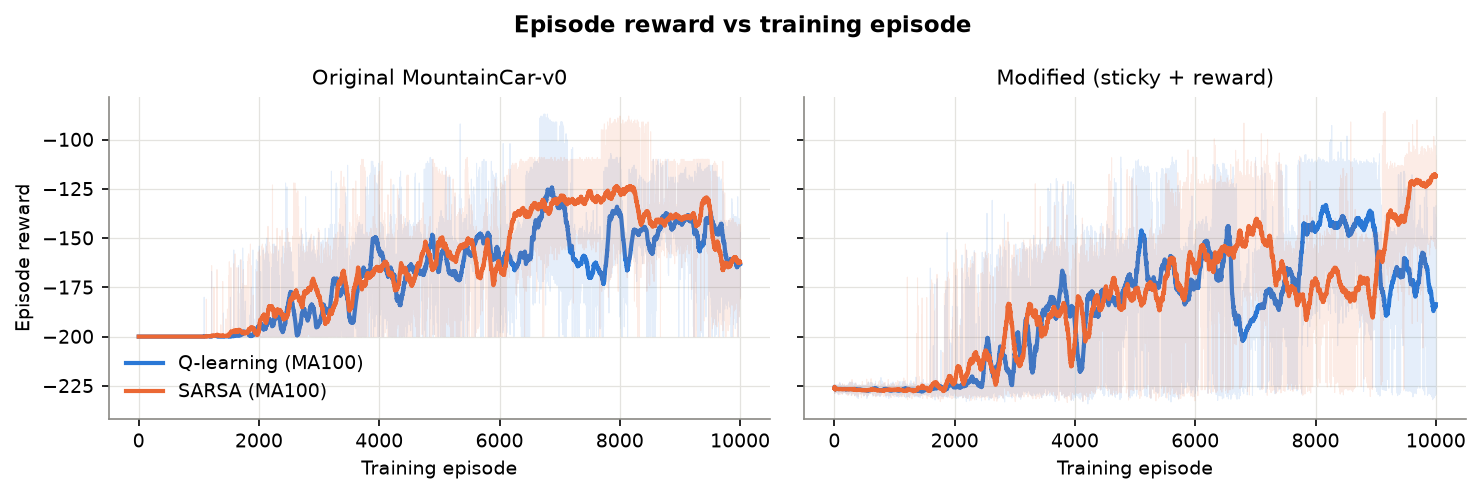

In [32]:
# Plotting helpers, then Fig. d.1: episode reward (raw + 100-episode moving average) per environment
from drl_sticky.plotting import (plot_metric_panels, plot_value_overlay, plot_rates, plot_policy_maps,
                                 plot_arrival_speed, plot_seed_robustness, plot_bins_ablation)
from drl_sticky.discretizer import UniformDiscretizer
plot_metric_panels(LOGS, "return", "Episode reward", "Episode reward vs training episode", "figures/fig1_reward.png")
Image("figures/fig1_reward.png", width=900)

In [33]:
display(Markdown(f"""
**Interpretation.** No agent reaches the flag for roughly the first thousand episodes. The first successes come at episode **{TR['qlearning_original']['first_success_episode']}** (Q-learning, original), **{TR['sarsa_original']['first_success_episode']}** (SARSA, original), **{TR['qlearning_modified']['first_success_episode']}** (Q-learning, modified) and **{TR['sarsa_modified']['first_success_episode']}** (SARSA, modified). Until then the reward is flat at -200 in the original environment. In the modified environment it is about {ma('qlearning_modified','return',1000):.0f}, which is -200 minus 0.2 for each of the ~{ma('qlearning_modified','pushes',1000):.0f} pushes an almost random policy selects. Once the flag has been found, the step cost propagates back through the table and the reward climbs as epsilon decays. The epsilon floor is reached at episode {int(CFG.eps_decay_frac*CFG.n_episodes)}.

*Q-learning vs SARSA.* In the **original** environment the two moving averages overlap for most of training. Over the last 500 episodes they score {TR['qlearning_original']['last_return']:.1f} (Q-learning) and {TR['sarsa_original']['last_return']:.1f} (SARSA). With epsilon = 0.01 the max-target and the epsilon-greedy target are almost the same. In the **modified** environment the curves are visibly noisier, because the sticky actuator randomly delays action switches and the same policy produces different outcomes. At the end of training {'SARSA' if TR['sarsa_modified']['last_return'] > TR['qlearning_modified']['last_return'] else 'Q-learning'} is ahead for this seed: {TR['sarsa_modified']['last_return']:.1f} (SARSA) vs {TR['qlearning_modified']['last_return']:.1f} (Q-learning) over the last 500 episodes. Section d.7 shows how much of this depends on the seed.

*Original vs modified.* The modified reward includes the -0.2 push penalty and the +20 bonus, so the two panels are not on the same scale. The bonus is why the best modified-environment episodes can beat the -1-per-step bound that holds in the original environment.
"""))


**Interpretation.** No agent reaches the flag for roughly the first thousand episodes. The first successes come at episode **1089** (Q-learning, original), **1125** (SARSA, original), **1595** (Q-learning, modified) and **1213** (SARSA, modified). Until then the reward is flat at -200 in the original environment. In the modified environment it is about -227, which is -200 minus 0.2 for each of the ~136 pushes an almost random policy selects. Once the flag has been found, the step cost propagates back through the table and the reward climbs as epsilon decays. The epsilon floor is reached at episode 7000.

*Q-learning vs SARSA.* In the **original** environment the two moving averages overlap for most of training. Over the last 500 episodes they score -156.0 (Q-learning) and -160.8 (SARSA). With epsilon = 0.01 the max-target and the epsilon-greedy target are almost the same. In the **modified** environment the curves are visibly noisier, because the sticky actuator randomly delays action switches and the same policy produces different outcomes. At the end of training SARSA is ahead for this seed: -121.1 (SARSA) vs -173.0 (Q-learning) over the last 500 episodes. Section d.7 shows how much of this depends on the seed.

*Original vs modified.* The modified reward includes the -0.2 push penalty and the +20 bonus, so the two panels are not on the same scale. The bonus is why the best modified-environment episodes can beat the -1-per-step bound that holds in the original environment.


### d.2 Average predicted value  mean over validation states of max_a Q(s,a)

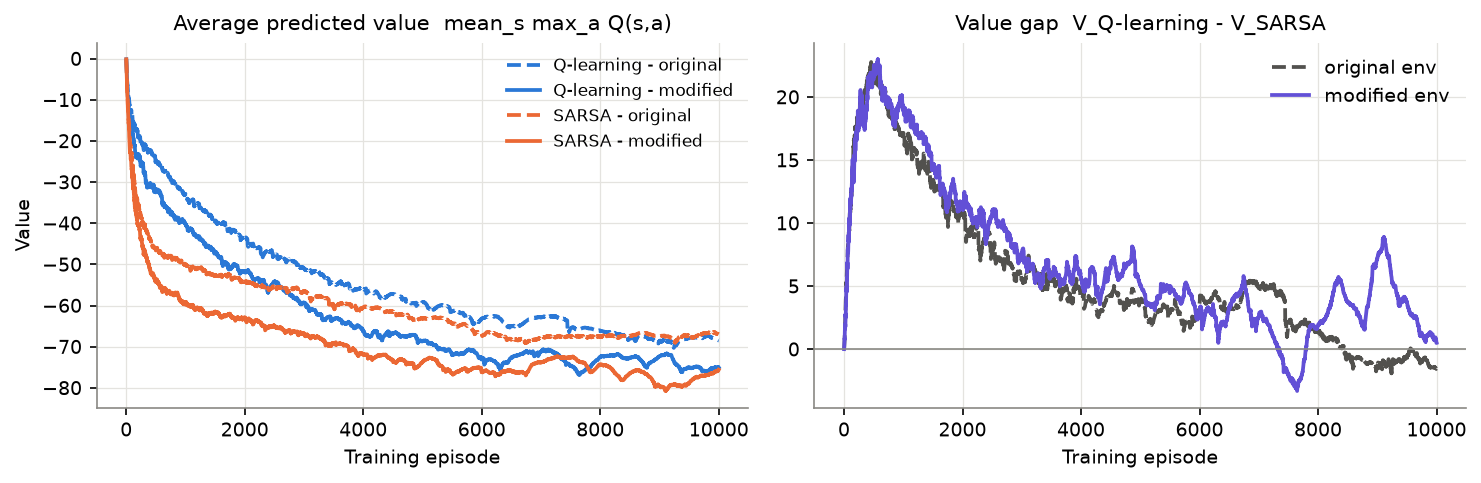

In [34]:
# Fig. d.2: average max_a Q(s,a) over the fixed validation set, and the Q-learning - SARSA gap
plot_value_overlay(LOGS, "figures/fig2_value.png")
Image("figures/fig2_value.png", width=900)

In [35]:
display(Markdown(f"""
**Interpretation.** All four curves start at **0**, the optimistic initial value, and fall as the agents learn the real cost-to-go. After the last episode the average predicted values are {TR['qlearning_original']['final_avg_max_q']:.1f} / {TR['sarsa_original']['final_avg_max_q']:.1f} (Q-learning / SARSA, original) and {TR['qlearning_modified']['final_avg_max_q']:.1f} / {TR['sarsa_modified']['final_avg_max_q']:.1f} (modified). Values in the modified environment are lower for two reasons. A push step costs 1.2 instead of 1. The +20 bonus is earned only at the end of an episode, so when discounted from a typical validation state about 100 steps away it is worth only around 20 * 0.99^100 ≈ 7.

*Q-learning vs SARSA.* While exploration is high, Q-learning's curve lies clearly **above** SARSA's. Q-learning bootstraps from max_a' Q(s',a'), the value of the greedy continuation. SARSA bootstraps from the action actually taken, and with epsilon close to 1 that is mostly a costly random action. The gap (right panel) peaks at {G84['original']['max']:.1f} (original) and {G84['modified']['max']:.1f} (modified) near episode {gap_peak_ep['original']}/{gap_peak_ep['modified']}. It then shrinks as epsilon decays, because the two targets converge. Averaged over the whole of training the gap is **{G84['original']['mean_all']:.2f}** in the original and **{G84['modified']['mean_all']:.2f}** in the modified environment. In the last 500 episodes it is {G84['original']['mean_last500']:.2f} and {G84['modified']['mean_last500']:.2f}. Question (e1) analyses this further.
"""))


**Interpretation.** All four curves start at **0**, the optimistic initial value, and fall as the agents learn the real cost-to-go. After the last episode the average predicted values are -68.5 / -66.9 (Q-learning / SARSA, original) and -75.1 / -75.6 (modified). Values in the modified environment are lower for two reasons. A push step costs 1.2 instead of 1. The +20 bonus is earned only at the end of an episode, so when discounted from a typical validation state about 100 steps away it is worth only around 20 * 0.99^100 ≈ 7.

*Q-learning vs SARSA.* While exploration is high, Q-learning's curve lies clearly **above** SARSA's. Q-learning bootstraps from max_a' Q(s',a'), the value of the greedy continuation. SARSA bootstraps from the action actually taken, and with epsilon close to 1 that is mostly a costly random action. The gap (right panel) peaks at 22.8 (original) and 23.0 (modified) near episode 458/572. It then shrinks as epsilon decays, because the two targets converge. Averaged over the whole of training the gap is **5.70** in the original and **6.94** in the modified environment. In the last 500 episodes it is -0.81 and 1.70. Question (e1) analyses this further.


### d.3 Success rate and gentle-arrival rate (moving average over the previous 100 episodes)

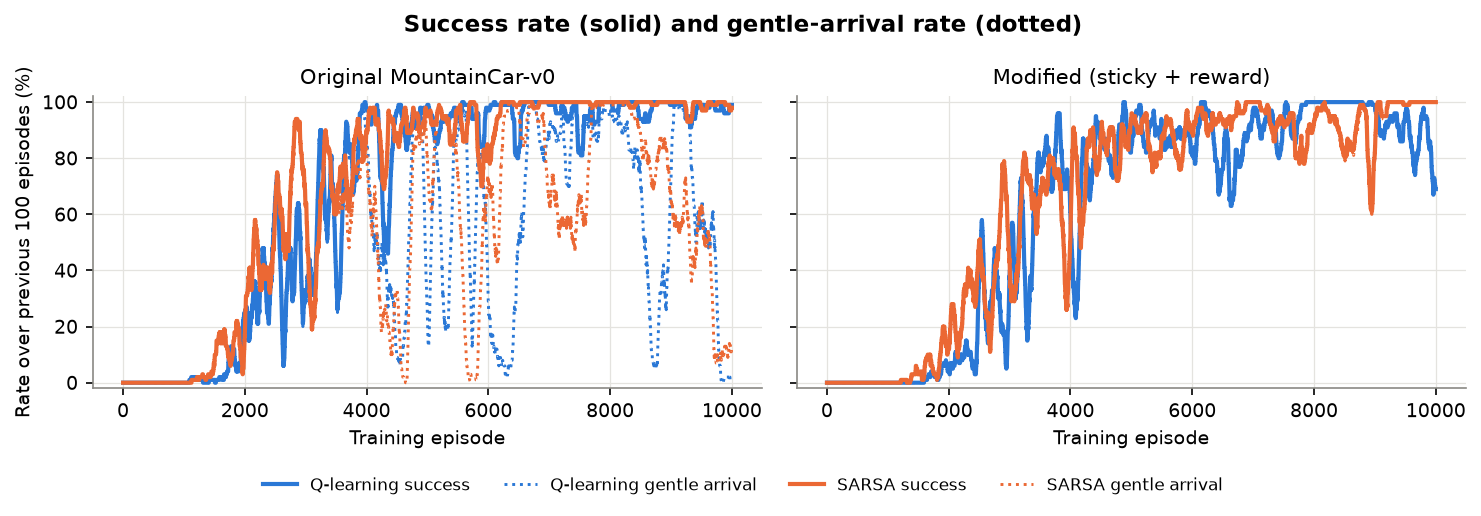

In [36]:
# Fig. d.3: success and gentle-arrival rates, moving average over the previous 100 episodes
plot_rates(LOGS, "figures/fig3_rates.png")
Image("figures/fig3_rates.png", width=900)

In [37]:
display(Markdown(f"""
**Interpretation.** Success rates rise from 0% to over 90% between roughly episode 1,500 and episode 4,000. Over the last 500 episodes they are {100*TR['qlearning_original']['last_success']:.1f}% / {100*TR['sarsa_original']['last_success']:.1f}% (Q-learning / SARSA, original) and {100*TR['qlearning_modified']['last_success']:.1f}% / {100*TR['sarsa_modified']['last_success']:.1f}% (modified). The sharp, short drops show how sensitive the greedy part of the policy still is: a few value updates can flip the action in frequently visited cells, and the rate recovers within a few hundred episodes.

*Gentle arrivals.* In the **original** environment the dotted gentle-arrival curves swing wildly. Nothing in the original reward separates a slow arrival from a fast one, so the arrival speed drifts around the 0.04 threshold: the mean arrival velocity over the last 500 episodes is {TR['qlearning_original']['last_arrival_velocity']:.3f} / {TR['sarsa_original']['last_arrival_velocity']:.3f}. Only {100*TR['qlearning_original']['last_gentle']:.1f}% / {100*TR['sarsa_original']['last_gentle']:.1f}% of the last 500 episodes end gently. In the **modified** environment the dotted curves sit **under the solid ones**: practically every arrival is gentle. Over the last 500 episodes the gentle rate is {100*TR['qlearning_modified']['last_gentle']:.1f}% / {100*TR['sarsa_modified']['last_gentle']:.1f}% against success of {100*TR['qlearning_modified']['last_success']:.1f}% / {100*TR['sarsa_modified']['last_success']:.1f}%. The bonus has taught both agents to control their arrival speed.
"""))


**Interpretation.** Success rates rise from 0% to over 90% between roughly episode 1,500 and episode 4,000. Over the last 500 episodes they are 98.0% / 99.0% (Q-learning / SARSA, original) and 83.2% / 100.0% (modified). The sharp, short drops show how sensitive the greedy part of the policy still is: a few value updates can flip the action in frequently visited cells, and the rate recovers within a few hundred episodes.

*Gentle arrivals.* In the **original** environment the dotted gentle-arrival curves swing wildly. Nothing in the original reward separates a slow arrival from a fast one, so the arrival speed drifts around the 0.04 threshold: the mean arrival velocity over the last 500 episodes is 0.036 / 0.040. Only 23.0% / 20.4% of the last 500 episodes end gently. In the **modified** environment the dotted curves sit **under the solid ones**: practically every arrival is gentle. Over the last 500 episodes the gentle rate is 83.2% / 100.0% against success of 83.2% / 100.0%. The bonus has taught both agents to control their arrival speed.


### d.4 Average number of push actions (0 or 2) selected per episode

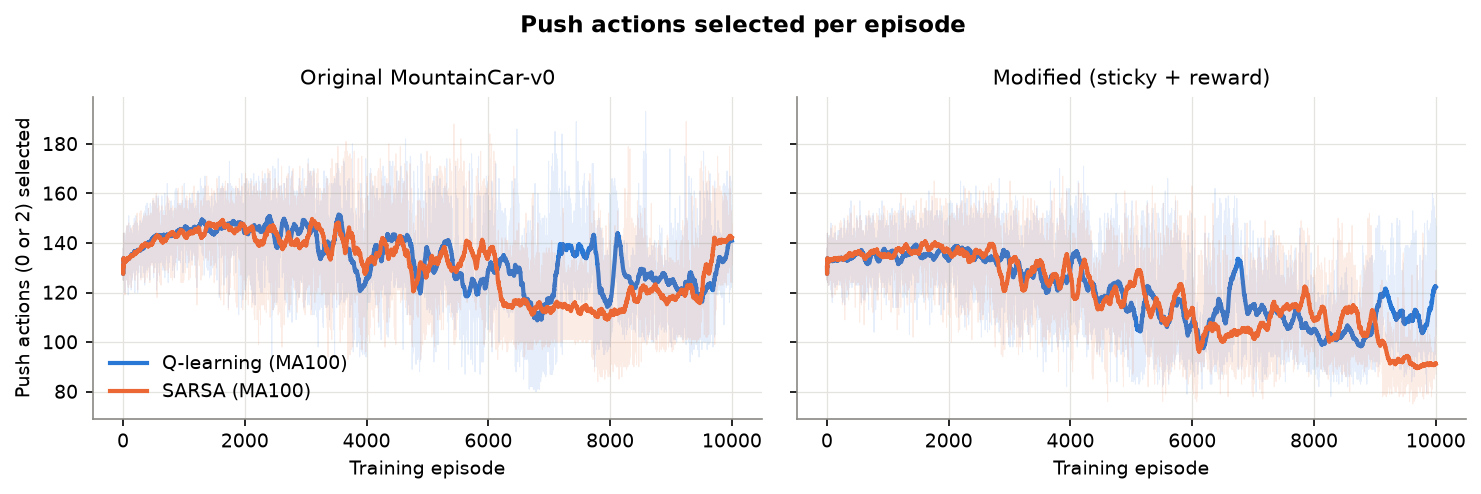

In [38]:
# Fig. d.4: number of push actions (0 or 2) selected per episode
plot_metric_panels(LOGS, "pushes", "Push actions (0 or 2) selected", "Push actions selected per episode", "figures/fig4_pushes.png")
Image("figures/fig4_pushes.png", width=900)

In [39]:
display(Markdown(f"""
**Interpretation.** At the start every agent selects about {ma('qlearning_original','pushes',100):.0f} pushes per 200-step episode. Under a near-random policy 2/3 of actions are pushes. In the **original** environment pushing is free, so the number of pushes stays high. Over the last 500 episodes it is {TR['qlearning_original']['last_pushes']:.1f} / {TR['sarsa_original']['last_pushes']:.1f} pushes per episode (Q-learning / SARSA), which is **{100*pf('qlearning_original'):.1f}% / {100*pf('sarsa_original'):.1f}% of all steps**. In the **modified** environment the count falls steadily to {TR['qlearning_modified']['last_pushes']:.1f} / {TR['sarsa_modified']['last_pushes']:.1f}, only **{100*pf('qlearning_modified'):.1f}% / {100*pf('sarsa_modified'):.1f}% of steps**. Shorter episodes account for part of the drop, but the per-step push fraction also falls by about {100*(0.5*(pf('qlearning_original')+pf('sarsa_original'))-0.5*(pf('qlearning_modified')+pf('sarsa_modified'))):.0f} percentage points. The energy penalty changes *how* the agents drive, not only how long. In the modified environment the two algorithms behave alike for most of training. {'SARSA' if TR['sarsa_modified']['last_pushes'] < TR['qlearning_modified']['last_pushes'] else 'Q-learning'} ends with fewer pushes for this seed.
"""))


**Interpretation.** At the start every agent selects about 134 pushes per 200-step episode. Under a near-random policy 2/3 of actions are pushes. In the **original** environment pushing is free, so the number of pushes stays high. Over the last 500 episodes it is 131.0 / 138.4 pushes per episode (Q-learning / SARSA), which is **84.0% / 86.1% of all steps**. In the **modified** environment the count falls steadily to 112.2 / 90.8, only **67.2% / 73.9% of steps**. Shorter episodes account for part of the drop, but the per-step push fraction also falls by about 14 percentage points. The energy penalty changes *how* the agents drive, not only how long. In the modified environment the two algorithms behave alike for most of training. SARSA ends with fewer pushes for this seed.


### d.5 Greedy policy maps (position x velocity)

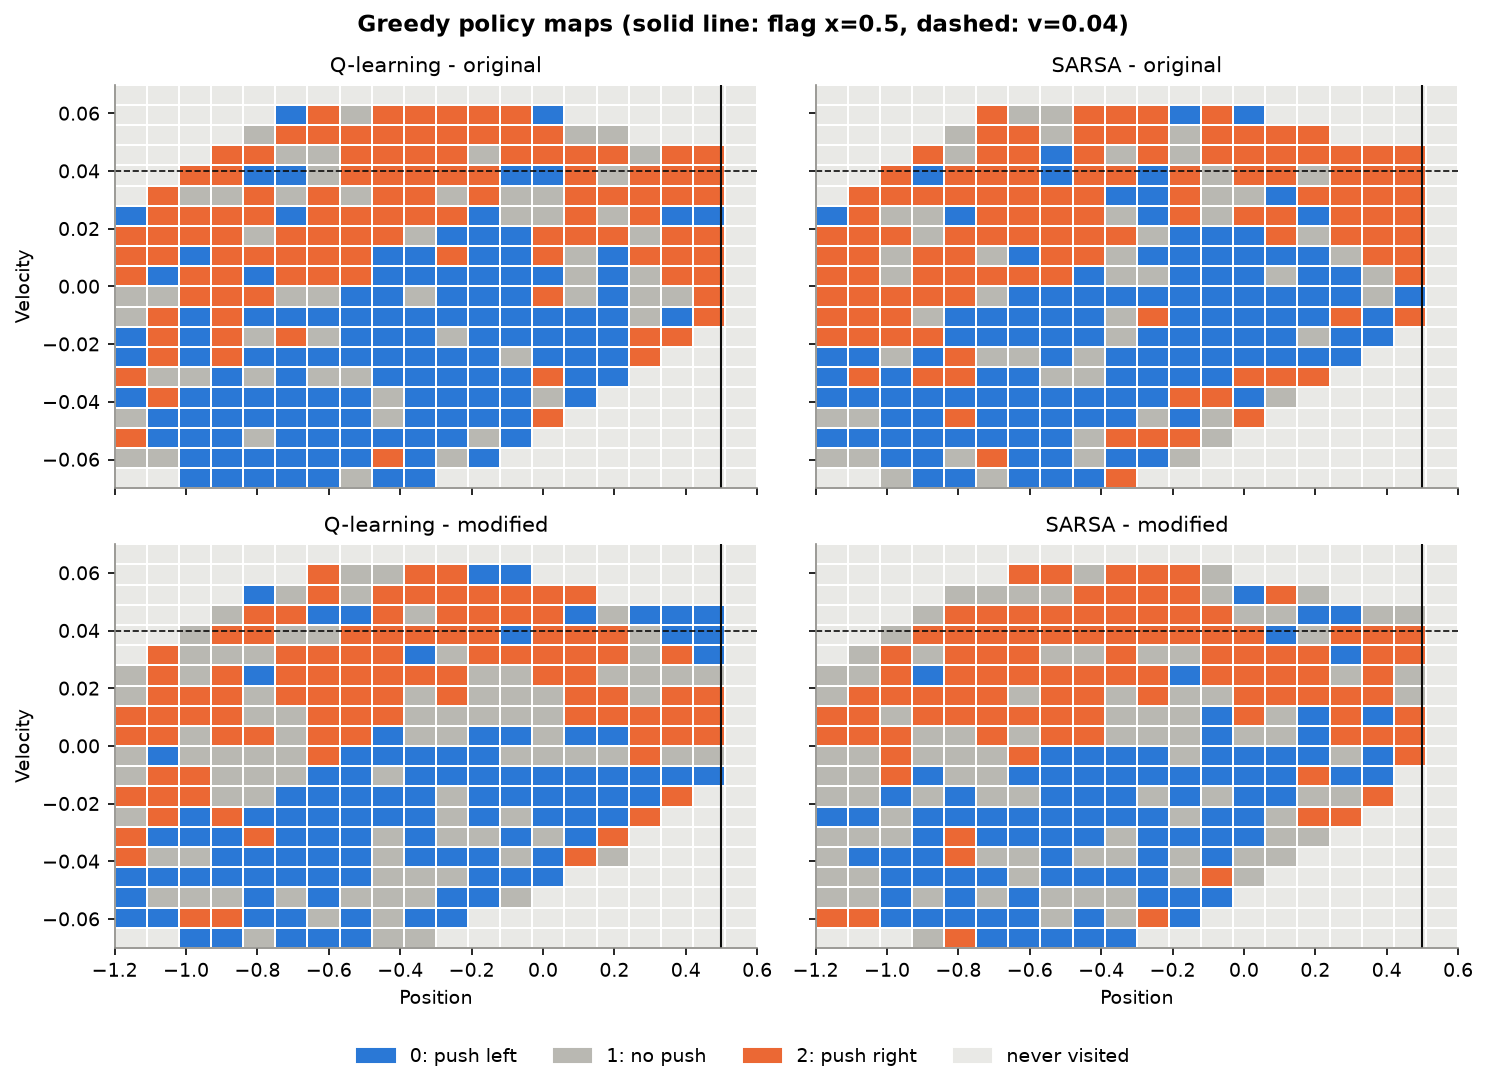

,visited_cells,total_cells,frac_left,frac_none,frac_right
qlearning_original,299.0,400.0,0.431,0.184,0.385
sarsa_original,299.0,400.0,0.411,0.181,0.408
qlearning_modified,296.0,400.0,0.358,0.304,0.338
sarsa_modified,295.0,400.0,0.319,0.325,0.356


In [40]:
# Fig. d.5: greedy action per (position, velocity) cell for the four agents + action shares
DISC = UniformDiscretizer((CFG.n_pos_bins, CFG.n_vel_bins))
plot_policy_maps(EV["_maps"], DISC, "figures/fig5_policy_maps.png")
display(Image("figures/fig5_policy_maps.png", width=820))
pd.DataFrame(R["policy_maps"]).T.round(3)

In [41]:
display(Markdown(f"""
**Interpretation.** All four maps show the energy-pumping strategy that solves MountainCar. The agent pushes **left (blue) while the velocity is negative** and **right (orange) while it is positive**, so the blue/orange boundary runs roughly along v = 0. The light cells were never visited. They are physically unreachable combinations, such as high speed at the far left or large negative speed next to the flag. Out of 400 cells {PM['qlearning_original']['visited_cells']}, {PM['sarsa_original']['visited_cells']}, {PM['qlearning_modified']['visited_cells']} and {PM['sarsa_modified']['visited_cells']} were visited.

*Original vs modified.* (i) The modified maps contain many more **no-push (grey)** cells: {100*PM['qlearning_modified']['frac_none']:.0f}% / {100*PM['sarsa_modified']['frac_none']:.0f}% of visited cells, against {100*PM['qlearning_original']['frac_none']:.0f}% / {100*PM['sarsa_original']['frac_none']:.0f}% in the original environment. These cells sit mostly around low speed and in the middle of the swing, where coasting costs little momentum and saves 0.2 per step. (ii) Near the flag at high speed (top-right corner, above the dashed v = 0.04 line), the original agents keep pushing right. The modified agents coast or even push left to **brake**, which brings them in under the 0.04 limit.

*Q-learning vs SARSA.* Within one environment the maps share the same structure. They differ mainly in individual, rarely visited cells, where the values are still close together and the different TD targets tip the argmax one way or the other.
"""))


**Interpretation.** All four maps show the energy-pumping strategy that solves MountainCar. The agent pushes **left (blue) while the velocity is negative** and **right (orange) while it is positive**, so the blue/orange boundary runs roughly along v = 0. The light cells were never visited. They are physically unreachable combinations, such as high speed at the far left or large negative speed next to the flag. Out of 400 cells 299, 299, 296 and 295 were visited.

*Original vs modified.* (i) The modified maps contain many more **no-push (grey)** cells: 30% / 33% of visited cells, against 18% / 18% in the original environment. These cells sit mostly around low speed and in the middle of the swing, where coasting costs little momentum and saves 0.2 per step. (ii) Near the flag at high speed (top-right corner, above the dashed v = 0.04 line), the original agents keep pushing right. The modified agents coast or even push left to **brake**, which brings them in under the 0.04 limit.

*Q-learning vs SARSA.* Within one environment the maps share the same structure. They differ mainly in individual, rarely visited cells, where the values are still close together and the different TD targets tip the argmax one way or the other.


### d.6 Greedy-policy evaluation: 100 test episodes, epsilon = 0, fixed seeds 10000-10099

In [42]:
# One table with the four required metrics (+ pushes and arrival speed)
names = {"qlearning_original": "Q-learning - Original", "sarsa_original": "SARSA - Original",
         "qlearning_modified": "Q-learning - Modified", "sarsa_modified": "SARSA - Modified"}
tab = pd.DataFrame({names[k]: {"mean reward": v["mean_reward"], "std reward": v["std_reward"],
                               "success rate": v["success_rate"], "gentle-arrival rate": v["gentle_rate"],
                               "mean episode length": v["mean_length"], "mean pushes / episode": v["mean_pushes"],
                               "mean arrival velocity": v["mean_arrival_velocity"]}
                    for k, v in R["evaluation"].items()}).T
tab.round(3)

,mean reward,std reward,success rate,gentle-arrival rate,mean episode length,mean pushes / episode,mean arrival velocity
Q-learning - Original,-160.300,10.214,1.00,0.00,160.30,139.42,0.043
SARSA - Original,-160.750,15.299,1.00,0.00,160.75,142.60,0.042
Q-learning - Modified,-155.564,21.911,0.95,0.95,152.18,111.92,0.022
SARSA - Modified,-117.588,13.645,1.00,1.00,119.19,91.99,0.019


In [43]:
display(Markdown(f"""
**Interpretation.** With epsilon = 0 on the same 100 test starts (and, for the modified environment, the same actuator-noise seeds), both **original-environment** agents reach the flag in {100*E['qlearning_original']['success_rate']:.0f}% / {100*E['sarsa_original']['success_rate']:.0f}% of episodes. Their gentle-arrival rate is only {100*E['qlearning_original']['gentle_rate']:.0f}% / {100*E['sarsa_original']['gentle_rate']:.0f}%, because they arrive at {E['qlearning_original']['mean_arrival_velocity']:.3f} / {E['sarsa_original']['mean_arrival_velocity']:.3f}, near or just above the threshold. In the **modified environment** Q-learning reaches {100*E['qlearning_modified']['success_rate']:.0f}% success, {100*E['qlearning_modified']['gentle_rate']:.0f}% gentle and a mean reward of {E['qlearning_modified']['mean_reward']:.1f}. SARSA reaches {100*E['sarsa_modified']['success_rate']:.0f}% success, {100*E['sarsa_modified']['gentle_rate']:.0f}% gentle and {E['sarsa_modified']['mean_reward']:.1f}, with {E['sarsa_modified']['mean_length']:.0f}-step episodes and {E['sarsa_modified']['mean_pushes']:.0f} pushes. In the modified environment every successful test episode is also a gentle arrival. For seed 84, {'SARSA' if E['sarsa_modified']['mean_reward'] > E['qlearning_modified']['mean_reward'] else 'Q-learning'} is the better agent under sticky actuators. Section d.7 tests whether this holds across seeds.
"""))


**Interpretation.** With epsilon = 0 on the same 100 test starts (and, for the modified environment, the same actuator-noise seeds), both **original-environment** agents reach the flag in 100% / 100% of episodes. Their gentle-arrival rate is only 0% / 0%, because they arrive at 0.043 / 0.042, near or just above the threshold. In the **modified environment** Q-learning reaches 95% success, 95% gentle and a mean reward of -155.6. SARSA reaches 100% success, 100% gentle and -117.6, with 119-step episodes and 92 pushes. In the modified environment every successful test episode is also a gentle arrival. For seed 84, SARSA is the better agent under sticky actuators. Section d.7 tests whether this holds across seeds.


### d.7 Additional evidence: arrival speed, robustness across seeds, and transfer to the sticky environment

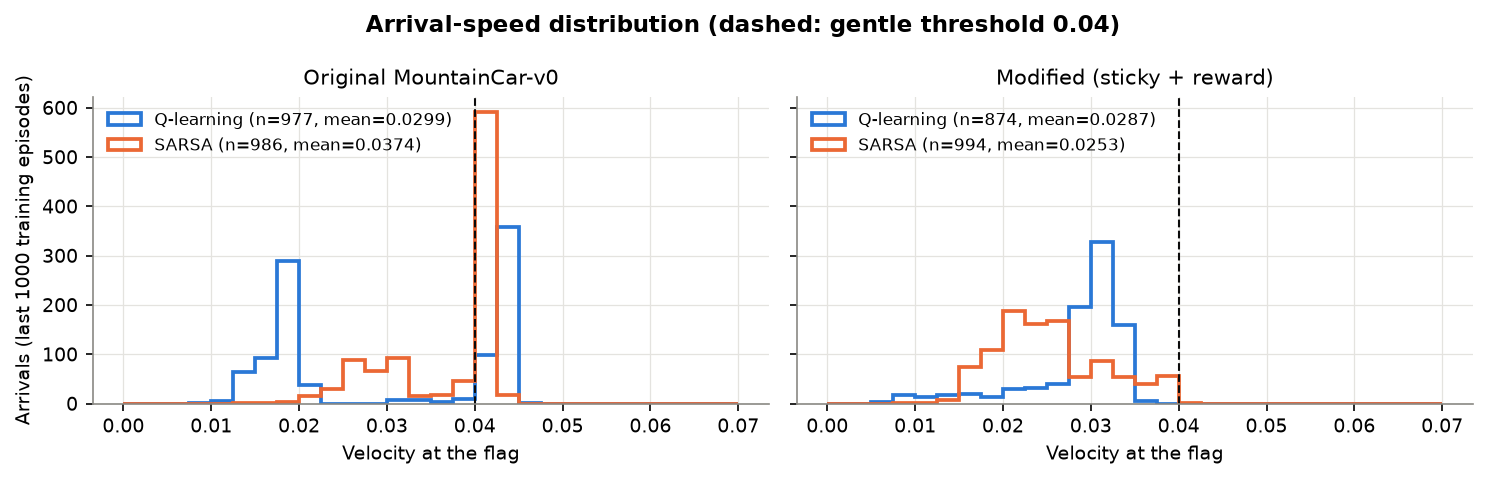

In [44]:
# Arrival-velocity histograms (last 1000 training episodes) for both environments
plot_arrival_speed(R["evaluation"], LOGS, "figures/fig6_arrival_speed.png")
Image("figures/fig6_arrival_speed.png", width=900)

In [45]:
# Every agent (including the two trained on the ORIGINAL env) tested in the MODIFIED env
cross = pd.DataFrame({names[k]: {m: v[m] for m in ["mean_reward", "success_rate", "gentle_rate", "mean_length", "mean_pushes"]}
                      for k, v in R["cross_evaluation_modified_env"].items()}).T
cross.round(3)

,mean_reward,success_rate,gentle_rate,mean_length,mean_pushes
Q-learning - Original,-187.598,1.00,0.03,160.34,139.29
SARSA - Original,-186.748,0.96,0.29,163.93,143.09
Q-learning - Modified,-155.564,0.95,0.95,152.18,111.92
SARSA - Modified,-117.588,1.00,1.00,119.19,91.99


In [46]:
display(Markdown(f"""
**Transfer test.** Every agent is evaluated in the **modified** environment. The two agents trained on the original environment still reach the flag ({100*CR['qlearning_original']['success_rate']:.0f}% / {100*CR['sarsa_original']['success_rate']:.0f}%), so the sticky actuator alone does not break a pumping policy. However, they collect only {CR['qlearning_original']['mean_reward']:.1f} / {CR['sarsa_original']['mean_reward']:.1f}, because they push on {100*CR['qlearning_original']['push_fraction']:.0f}% of steps and arrive gently in only {100*CR['qlearning_original']['gentle_rate']:.0f}% / {100*CR['sarsa_original']['gentle_rate']:.0f}% of episodes. The agents trained in the modified environment score {CR['qlearning_modified']['mean_reward']-CR['qlearning_original']['mean_reward']:.1f} (Q-learning) and {CR['sarsa_modified']['mean_reward']-CR['sarsa_original']['mean_reward']:.1f} (SARSA) reward units more in the same environment. Training under the modified reward is what produces the gentle, energy-saving behaviour.
"""))


**Transfer test.** Every agent is evaluated in the **modified** environment. The two agents trained on the original environment still reach the flag (100% / 96%), so the sticky actuator alone does not break a pumping policy. However, they collect only -187.6 / -186.7, because they push on 87% of steps and arrive gently in only 3% / 29% of episodes. The agents trained in the modified environment score 32.0 (Q-learning) and 69.2 (SARSA) reward units more in the same environment. Training under the modified reward is what produces the gentle, energy-saving behaviour.


In [47]:
# Robustness: repeat the 4 runs for seeds 84-88 and the discretization ablation (parallel processes)
t0 = time.time()
ROB = X.run_robustness(CFG, VAL, seeds=[84, 85, 86, 87, 88])
R["multi_seed"] = {k: v for k, v in ROB.items() if k != "bins_ablation"}
R["bins_ablation"] = ROB["bins_ablation"]
print(f"{len(ROB['per_seed'])} seed runs + ablation finished in {time.time()-t0:.0f}s")
ms = pd.DataFrame({names[k]: {f"{m} (mean +- std)": f"{v[m]['mean']:.3f} +- {v[m]['std']:.3f}" for m in
                   ["mean_reward", "success_rate", "gentle_rate", "mean_length", "mean_pushes", "avg_max_q_last500"]}
                   for k, v in ROB["summary"].items()}).T
ms

20 seed runs + ablation finished in 199s


,mean_reward (mean +- std),success_rate (mean +- std),gentle_rate (mean +- std),mean_length (mean +- std),mean_pushes (mean +- std),avg_max_q_last500 (mean +- std)
Q-learning - Original,-143.104 +- 11.508,0.994 +- 0.012,0.540 +- 0.334,143.104 +- 11.508,124.234 +- 10.254,-67.346 +- 0.585
SARSA - Original,-143.680 +- 10.699,1.000 +- 0.000,0.600 +- 0.490,143.680 +- 10.699,127.256 +- 9.899,-69.171 +- 1.548
Q-learning - Modified,-139.268 +- 12.749,0.990 +- 0.020,0.990 +- 0.020,138.822 +- 11.474,101.230 +- 5.941,-75.432 +- 1.336
SARSA - Modified,-156.278 +- 31.385,0.840 +- 0.203,0.822 +- 0.214,151.568 +- 24.967,104.550 +- 15.442,-76.528 +- 1.039


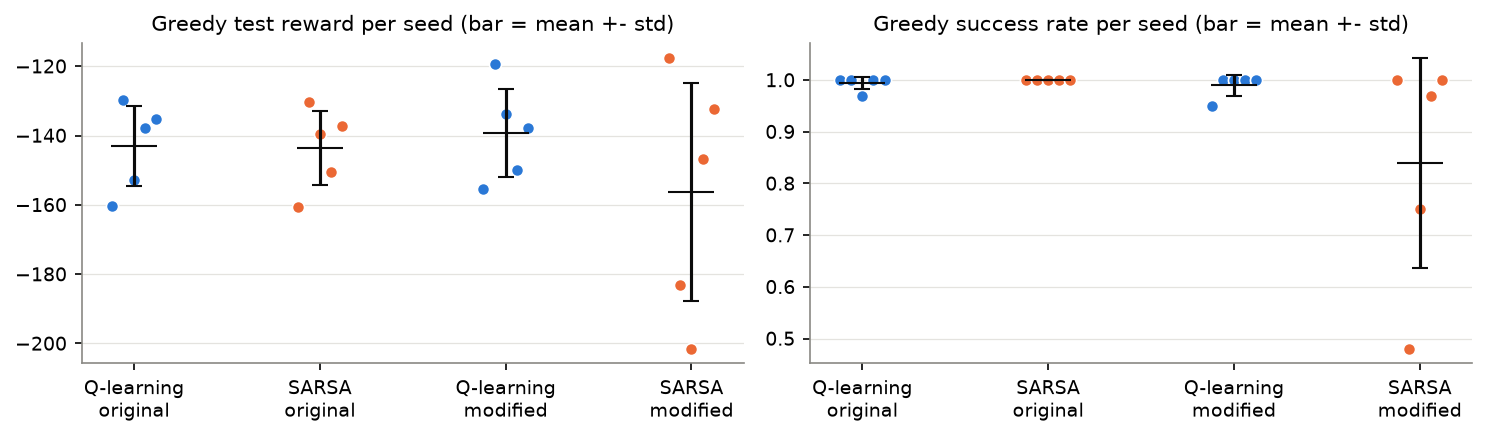

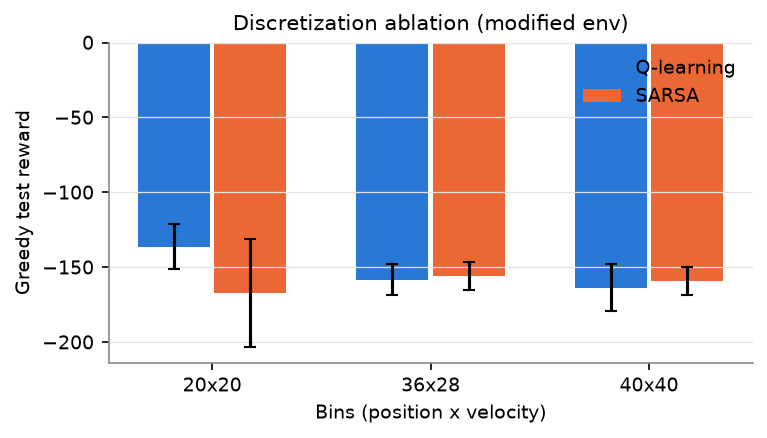

In [48]:
# Per-seed greedy results and the discretization ablation
plot_seed_robustness(ROB["summary"], "figures/fig7_seeds.png")
plot_bins_ablation(ROB["bins_ablation"]["results"], "figures/fig8_bins_ablation.png")
display(Image("figures/fig7_seeds.png", width=900))
Image("figures/fig8_bins_ablation.png", width=480)

In [49]:
# Multi-seed quantities used by the robustness text and the discussion
MS, GP = R["multi_seed"]["summary"], R["multi_seed"]["value_gap_phases"]
n_seeds = len(R["multi_seed"]["seeds"])
sarsa_wins = int(sum(s > q for s, q in zip(MS["sarsa_modified"]["mean_reward"]["values"],
                                           MS["qlearning_modified"]["mean_reward"]["values"])))
gap_larger_all = int(sum(m > o for m, o in zip(GP["modified"]["all"]["values"], GP["original"]["all"]["values"])))
gap_larger_first = int(sum(m > o for m, o in zip(GP["modified"]["first20pct"]["values"],
                                                 GP["original"]["first20pct"]["values"])))

In [50]:
display(Markdown(f"""
**Robustness across seeds (84-88) and discretization.** A single seed is not enough to rank the algorithms. Over five seeds:

| Agent | greedy test reward | success | gentle | training reward (last 500, epsilon = 0.01) |
|---|---|---|---|---|
| Q-learning - original | {MS['qlearning_original']['mean_reward']['mean']:.1f} +- {MS['qlearning_original']['mean_reward']['std']:.1f} | {100*MS['qlearning_original']['success_rate']['mean']:.0f}% | {100*MS['qlearning_original']['gentle_rate']['mean']:.0f}% | {MS['qlearning_original']['train_last500_return']['mean']:.1f} +- {MS['qlearning_original']['train_last500_return']['std']:.1f} |
| SARSA - original | {MS['sarsa_original']['mean_reward']['mean']:.1f} +- {MS['sarsa_original']['mean_reward']['std']:.1f} | {100*MS['sarsa_original']['success_rate']['mean']:.0f}% | {100*MS['sarsa_original']['gentle_rate']['mean']:.0f}% | {MS['sarsa_original']['train_last500_return']['mean']:.1f} +- {MS['sarsa_original']['train_last500_return']['std']:.1f} |
| Q-learning - modified | {MS['qlearning_modified']['mean_reward']['mean']:.1f} +- {MS['qlearning_modified']['mean_reward']['std']:.1f} | {100*MS['qlearning_modified']['success_rate']['mean']:.0f}% | {100*MS['qlearning_modified']['gentle_rate']['mean']:.0f}% | {MS['qlearning_modified']['train_last500_return']['mean']:.1f} +- {MS['qlearning_modified']['train_last500_return']['std']:.1f} |
| SARSA - modified | {MS['sarsa_modified']['mean_reward']['mean']:.1f} +- {MS['sarsa_modified']['mean_reward']['std']:.1f} | {100*MS['sarsa_modified']['success_rate']['mean']:.0f}% | {100*MS['sarsa_modified']['gentle_rate']['mean']:.0f}% | {MS['sarsa_modified']['train_last500_return']['mean']:.1f} +- {MS['sarsa_modified']['train_last500_return']['std']:.1f} |

In the **original** environment the two algorithms cannot be told apart. In the **modified** environment SARSA beats Q-learning on greedy test reward in **{sarsa_wins} of {n_seeds}** seeds, with a median of {np.median(MS['sarsa_modified']['mean_reward']['values']):.1f} against {np.median(MS['qlearning_modified']['mean_reward']['values']):.1f} for Q-learning. Its spread is much larger: on its worst seed the greedy SARSA policy succeeds in only {100*min(MS['sarsa_modified']['success_rate']['values']):.0f}% of test episodes. Q-learning's worst is {100*min(MS['qlearning_modified']['success_rate']['values']):.0f}%. The strong seed-84 SARSA result is therefore one good draw, not a typical outcome.

*Discretization ablation* (modified environment, seeds {R['bins_ablation']['seeds']}): {', '.join(f"{b}: Q {v['qlearning']['mean']:.1f}, SARSA {v['sarsa']['mean']:.1f}" for b, v in R['bins_ablation']['results'].items())}. Q-learning does best with 20x20. For SARSA, the finer grids give a smaller seed-to-seed spread (std {R['bins_ablation']['results']['36x28']['sarsa']['std']:.1f} at 36x28 against {R['bins_ablation']['results']['20x20']['sarsa']['std']:.1f} at 20x20).
"""))


**Robustness across seeds (84-88) and discretization.** A single seed is not enough to rank the algorithms. Over five seeds:

| Agent | greedy test reward | success | gentle | training reward (last 500, epsilon = 0.01) |
|---|---|---|---|---|
| Q-learning - original | -143.1 +- 11.5 | 99% | 54% | -145.0 +- 10.6 |
| SARSA - original | -143.7 +- 10.7 | 100% | 60% | -150.1 +- 7.6 |
| Q-learning - modified | -139.3 +- 12.7 | 99% | 99% | -152.0 +- 13.8 |
| SARSA - modified | -156.3 +- 31.4 | 84% | 82% | -144.2 +- 17.0 |

In the **original** environment the two algorithms cannot be told apart. In the **modified** environment SARSA beats Q-learning on greedy test reward in **3 of 5** seeds, with a median of -146.7 against -137.9 for Q-learning. Its spread is much larger: on its worst seed the greedy SARSA policy succeeds in only 48% of test episodes. Q-learning's worst is 95%. The strong seed-84 SARSA result is therefore one good draw, not a typical outcome.

*Discretization ablation* (modified environment, seeds [84, 85, 86]): 20x20: Q -136.2, SARSA -167.4, 36x28: Q -158.2, SARSA -156.1, 40x40: Q -163.6, SARSA -159.2. Q-learning does best with 20x20. For SARSA, the finer grids give a smaller seed-to-seed spread (std 9.4 at 36x28 against 36.0 at 20x20).


## (e) Discussion

In [51]:
# Numbers used in the discussion
calib = pd.DataFrame(R["value_calibration"]).T
calib.columns = ["mean predicted max Q", "mean actual greedy return", "bias (pred - actual)", "MAE"]
display(calib.round(3))
gaps = pd.DataFrame({env: {"gap seed 84 (last 500 ep.)": R["value_gap_seed84"][env]["mean_last500"],
                           "gap 5 seeds mean": R["multi_seed"]["value_gap_last500"][env]["mean"],
                           "gap 5 seeds std": R["multi_seed"]["value_gap_last500"][env]["std"]}
                     for env in ["original", "modified"]}).T
display(gaps.round(3))
nm = R["verification"]["non_markov"]
pd.DataFrame([nm]).T.rename(columns={0: "value"})

,mean predicted max Q,mean actual greedy return,bias (pred - actual),MAE
qlearning_original,-68.423,-78.078,9.654,9.812
sarsa_original,-66.911,-79.098,12.187,12.187
qlearning_modified,-74.925,-82.132,7.207,7.318
sarsa_modified,-75.471,-74.863,-0.609,6.465


,gap seed 84 (last 500 ep.),gap 5 seeds mean,gap 5 seeds std
original,-0.806,1.826,1.975
modified,1.700,1.096,1.995


,value
selected_a,2.000000
mean_dv_given_aprev_2,0.000999
mean_dv_given_aprev_0,0.000619
p_exec_right_given_aprev_2,1.000000
p_exec_right_given_aprev_0,0.798184
n_aprev_2,33040.000000
n_aprev_0,32827.000000
p_prev_selected_equals_aprev,0.867209


In [52]:
display(Markdown(f"""
### (e1) Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?
**{'Yes, but only moderately, and mainly while the agents still explore.' if GP['modified']['all']['mean'] > GP['original']['all']['mean'] else 'No, not in our measurements.'}** The value gap is V_Q-learning - V_SARSA, where V is the average of max_a Q(s,a) over the fixed validation set (Fig. d.2, right).

* **Seed 84.** Averaged over all {CFG.n_episodes} episodes the gap is {G84['original']['mean_all']:.2f} (original) vs **{G84['modified']['mean_all']:.2f}** (modified). In the first 20% of training (epsilon > {CFG.epsilon(int(0.2*CFG.n_episodes)):.2f}) it is {G84['original']['first20pct']:.2f} vs **{G84['modified']['first20pct']:.2f}**, and between 20% and 70% of training it is {G84['original']['middle']:.2f} vs **{G84['modified']['middle']:.2f}**.
* **Five seeds.** The gap over the whole of training is {GP['original']['all']['mean']:.2f} +- {GP['original']['all']['std']:.2f} (original) vs **{GP['modified']['all']['mean']:.2f} +- {GP['modified']['all']['std']:.2f}** (modified). It is larger in the modified environment in **{gap_larger_all} of {n_seeds}** seeds, with a paired difference of {GP['modified_minus_original_all']['mean']:.2f} +- {GP['modified_minus_original_all']['std']:.2f}. In the high-exploration phase (first 20%) it is larger in **{gap_larger_first} of {n_seeds}** seeds ({GP['original']['first20pct']['mean']:.2f} vs {GP['modified']['first20pct']['mean']:.2f}).
* **End of training.** At epsilon = 0.01 the gap is small and noisy in both environments ({GP['original']['last5pct']['mean']:.2f} +- {GP['original']['last5pct']['std']:.2f} vs {GP['modified']['last5pct']['mean']:.2f} +- {GP['modified']['last5pct']['std']:.2f}), so there is no difference left to detect.

*Why.* Q-learning's target max_a' Q(s',a') assumes that the best next action will be chosen **and executed**. SARSA's target Q(s',a') uses the action actually chosen, so its estimate already contains the cost of exploration. The sticky actuator adds a second, hidden source of noise. Every attempted switch, including exploratory ones, is delayed with probability 0.2, and the outcome of (s,a) depends on the unobserved a_prev. The values in each cell are therefore noisier. Taking a max over noisy estimates is biased upward (maximisation bias), while SARSA's sampled target is not, so the two estimates drift further apart. As epsilon reaches 0.01 the greedy and epsilon-greedy targets coincide and the gap closes in both environments.

*Additional check (greedy Monte-Carlo returns from 200 validation states).* We compare predicted values with actual returns, reported as bias = predicted - actual. In the original environment both algorithms show a positive bias: {CAL['qlearning_original']['bias']:.1f} for Q-learning and {CAL['sarsa_original']['bias']:.1f} for SARSA. This is the optimism left by state aggregation. In the modified environment, Q-learning still overestimates by {CAL['qlearning_modified']['bias']:.1f}, while SARSA's prediction is almost unbiased ({CAL['sarsa_modified']['bias']:.1f}). For seed 84, then, the on-policy estimate is the better-calibrated one under sticky actuators. This check uses one seed, so we treat it as supporting evidence only.
"""))


### (e1) Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?
**Yes, but only moderately, and mainly while the agents still explore.** The value gap is V_Q-learning - V_SARSA, where V is the average of max_a Q(s,a) over the fixed validation set (Fig. d.2, right).

* **Seed 84.** Averaged over all 10000 episodes the gap is 5.70 (original) vs **6.94** (modified). In the first 20% of training (epsilon > 0.27) it is 15.53 vs **16.36**, and between 20% and 70% of training it is 4.78 vs **5.81**.
* **Five seeds.** The gap over the whole of training is 5.97 +- 0.38 (original) vs **7.06 +- 0.90** (modified). It is larger in the modified environment in **4 of 5** seeds, with a paired difference of 1.08 +- 1.10. In the high-exploration phase (first 20%) it is larger in **5 of 5** seeds (15.41 vs 16.63).
* **End of training.** At epsilon = 0.01 the gap is small and noisy in both environments (1.83 +- 1.97 vs 1.09 +- 1.99), so there is no difference left to detect.

*Why.* Q-learning's target max_a' Q(s',a') assumes that the best next action will be chosen **and executed**. SARSA's target Q(s',a') uses the action actually chosen, so its estimate already contains the cost of exploration. The sticky actuator adds a second, hidden source of noise. Every attempted switch, including exploratory ones, is delayed with probability 0.2, and the outcome of (s,a) depends on the unobserved a_prev. The values in each cell are therefore noisier. Taking a max over noisy estimates is biased upward (maximisation bias), while SARSA's sampled target is not, so the two estimates drift further apart. As epsilon reaches 0.01 the greedy and epsilon-greedy targets coincide and the gap closes in both environments.

*Additional check (greedy Monte-Carlo returns from 200 validation states).* We compare predicted values with actual returns, reported as bias = predicted - actual. In the original environment both algorithms show a positive bias: 9.7 for Q-learning and 12.2 for SARSA. This is the optimism left by state aggregation. In the modified environment, Q-learning still overestimates by 7.2, while SARSA's prediction is almost unbiased (-0.6). For seed 84, then, the on-policy estimate is the better-calibrated one under sticky actuators. This check uses one seed, so we treat it as supporting evidence only.


In [53]:
display(Markdown(f"""
### (e2) Why is the modified environment non-Markovian with respect to the observation, and how does this affect credit assignment?
An observation is Markov if P(o_t+1, r_t | o_t, a_t) does not depend on anything earlier. In the modified environment the executed action depends on **a_prev**, the action executed on the previous step. a_prev is not part of the observation (position, velocity). The true state is (x, v, a_prev), and the agent sees only (x, v). The same observation and the same selected action can therefore lead to different next-state distributions. We measured this directly (random policy, {NM['n_aprev_2']+NM['n_aprev_0']:,} steps where the agent selected *push right*):

| hidden a_prev | P(push right is executed) | mean change in velocity |
|---|---|---|
| 2 (right) | {NM['p_exec_right_given_aprev_2']:.3f} | {NM['mean_dv_given_aprev_2']:.5f} |
| 0 (left) | {NM['p_exec_right_given_aprev_0']:.3f} | {NM['mean_dv_given_aprev_0']:.5f} |

The table shows the agent is in a **POMDP**. The hidden variable is also produced by the agent's own past actions, so the effective transition probabilities of an observed state depend on the policy itself. This breaks the Markov assumption behind the convergence guarantees of tabular TD control.

**Effects on credit assignment.**
1. **Misattributed credit.** The energy penalty is charged on the *selected* action a_t, but the motion comes from a_exec, which after a stuck step is the *previous* action. The update of Q(s_t, a_t) is credited with the effect of a_t-1, and the effect of a_t only appears one or more steps later, where it is credited to whatever pair is updated then.
2. **Delayed and spread-out consequences.** A switch decision succeeds after a geometric number of attempts (mean 1/0.8 = 1.25 steps). Its consequence is spread over several transitions that one-step TD can only chain together by bootstrapping from aliased states.
3. **Noisier, aliased targets.** Every discretized cell mixes visits with different a_prev, so each target averages over the hidden variable. Learning slows down. The first success came at episode {TR['qlearning_modified']['first_success_episode']} for Q-learning in the modified environment against {TR['qlearning_original']['first_success_episode']} in the original, and at {TR['sarsa_modified']['first_success_episode']} vs {TR['sarsa_original']['first_success_episode']} for SARSA. Switching actions also becomes intrinsically risky, which favours policies that switch rarely.
"""))


### (e2) Why is the modified environment non-Markovian with respect to the observation, and how does this affect credit assignment?
An observation is Markov if P(o_t+1, r_t | o_t, a_t) does not depend on anything earlier. In the modified environment the executed action depends on **a_prev**, the action executed on the previous step. a_prev is not part of the observation (position, velocity). The true state is (x, v, a_prev), and the agent sees only (x, v). The same observation and the same selected action can therefore lead to different next-state distributions. We measured this directly (random policy, 65,867 steps where the agent selected *push right*):

| hidden a_prev | P(push right is executed) | mean change in velocity |
|---|---|---|
| 2 (right) | 1.000 | 0.00100 |
| 0 (left) | 0.798 | 0.00062 |

The table shows the agent is in a **POMDP**. The hidden variable is also produced by the agent's own past actions, so the effective transition probabilities of an observed state depend on the policy itself. This breaks the Markov assumption behind the convergence guarantees of tabular TD control.

**Effects on credit assignment.**
1. **Misattributed credit.** The energy penalty is charged on the *selected* action a_t, but the motion comes from a_exec, which after a stuck step is the *previous* action. The update of Q(s_t, a_t) is credited with the effect of a_t-1, and the effect of a_t only appears one or more steps later, where it is credited to whatever pair is updated then.
2. **Delayed and spread-out consequences.** A switch decision succeeds after a geometric number of attempts (mean 1/0.8 = 1.25 steps). Its consequence is spread over several transitions that one-step TD can only chain together by bootstrapping from aliased states.
3. **Noisier, aliased targets.** Every discretized cell mixes visits with different a_prev, so each target averages over the hidden variable. Learning slows down. The first success came at episode 1595 for Q-learning in the modified environment against 1089 in the original, and at 1213 vs 1125 for SARSA. Switching actions also becomes intrinsically risky, which favours policies that switch rarely.


In [54]:
display(Markdown(f"""
### (e3) Do the energy penalty and the gentle-arrival bonus encourage fewer pushes, or a slower, more controlled arrival?
**Both: fewer pushes and a controlled arrival, with little change in trip length.**

* **Fewer pushes (push-count plot, d.4).** Over the last 500 training episodes the agents push on {100*pf('qlearning_original'):.1f}% / {100*pf('sarsa_original'):.1f}% of steps in the original environment, against {100*pf('qlearning_modified'):.1f}% / {100*pf('sarsa_modified'):.1f}% in the modified one (Q-learning / SARSA). In the greedy test the counts fall from {E['qlearning_original']['mean_pushes']:.0f} / {E['sarsa_original']['mean_pushes']:.0f} to **{E['qlearning_modified']['mean_pushes']:.0f} / {E['sarsa_modified']['mean_pushes']:.0f}** pushes per episode. Over five seeds they fall from {MS['qlearning_original']['mean_pushes']['mean']:.0f} / {MS['sarsa_original']['mean_pushes']['mean']:.0f} to {MS['qlearning_modified']['mean_pushes']['mean']:.0f} / {MS['sarsa_modified']['mean_pushes']['mean']:.0f}.
* **Policy maps (d.5).** The share of no-push cells rises from {100*PM['qlearning_original']['frac_none']:.0f}% / {100*PM['sarsa_original']['frac_none']:.0f}% to {100*PM['qlearning_modified']['frac_none']:.0f}% / {100*PM['sarsa_modified']['frac_none']:.0f}%. Near the flag at high speed the modified agents coast or brake instead of pushing right.
* **Controlled arrival (arrival-speed statistics, d.7).** The original agents arrive at a mean speed of {E['qlearning_original']['mean_arrival_velocity']:.3f} / {E['sarsa_original']['mean_arrival_velocity']:.3f} in the greedy test, with a gentle rate of {100*E['qlearning_original']['gentle_rate']:.0f}% / {100*E['sarsa_original']['gentle_rate']:.0f}%. The modified agents arrive at **{E['qlearning_modified']['mean_arrival_velocity']:.3f} / {E['sarsa_modified']['mean_arrival_velocity']:.3f}** with a gentle rate of **{100*E['qlearning_modified']['gentle_rate']:.0f}% / {100*E['sarsa_modified']['gentle_rate']:.0f}%**. In the last 1,000 training episodes, {n_fast_mod} of the modified agents' arrivals exceeded 0.04, compared with {n_fast_orig} for the original agents. Over five seeds the gentle rate is {100*MS['qlearning_original']['gentle_rate']['mean']:.0f}% / {100*MS['sarsa_original']['gentle_rate']['mean']:.0f}% (original) vs {100*MS['qlearning_modified']['gentle_rate']['mean']:.0f}% / {100*MS['sarsa_modified']['gentle_rate']['mean']:.0f}% (modified).
* **Trip length.** Greedy episodes in the modified environment last {E['qlearning_modified']['mean_length']:.0f} / {E['sarsa_modified']['mean_length']:.0f} steps, against {E['qlearning_original']['mean_length']:.0f} / {E['sarsa_original']['mean_length']:.0f} in the original. Over five seeds: {MS['qlearning_modified']['mean_length']['mean']:.0f} / {MS['sarsa_modified']['mean_length']['mean']:.0f} vs {MS['qlearning_original']['mean_length']['mean']:.0f} / {MS['sarsa_original']['mean_length']['mean']:.0f}. The changes are within the seed-to-seed spread of about {max(MS[k]['mean_length']['std'] for k in MS):.0f} steps (the largest std), so the agents do not systematically drive slower. {('The longer five-seed SARSA mean comes from its weak seeds ' + ', '.join(str(r['seed']) for r in R['multi_seed']['per_seed'] if r['algo']=='sarsa' and r['env']=='modified' and r['eval']['success_rate'] < 0.9) + ', whose greedy policies fail in part of the test episodes (truncated at 200 steps) or take long detours. Without them SARSA averages ' + format(np.mean([r['eval']['mean_length'] for r in R['multi_seed']['per_seed'] if r['algo']=='sarsa' and r['env']=='modified' and r['eval']['success_rate'] >= 0.9]), '.0f') + ' steps.') if MS['sarsa_modified']['mean_length']['mean'] > MS['sarsa_original']['mean_length']['mean'] else ''}

The penalty of 0.2 is small next to the step cost of 1, and the +20 bonus is large. The best strategy is therefore still to reach the flag quickly, while dropping pushes that add little energy and shedding speed in the last few metres. The bonus is what controls arrival speed, since the original agents sit right at the 0.04 boundary by chance. The penalty is what removes unnecessary pushes.
"""))


### (e3) Do the energy penalty and the gentle-arrival bonus encourage fewer pushes, or a slower, more controlled arrival?
**Both: fewer pushes and a controlled arrival, with little change in trip length.**

* **Fewer pushes (push-count plot, d.4).** Over the last 500 training episodes the agents push on 84.0% / 86.1% of steps in the original environment, against 67.2% / 73.9% in the modified one (Q-learning / SARSA). In the greedy test the counts fall from 139 / 143 to **112 / 92** pushes per episode. Over five seeds they fall from 124 / 127 to 101 / 105.
* **Policy maps (d.5).** The share of no-push cells rises from 18% / 18% to 30% / 33%. Near the flag at high speed the modified agents coast or brake instead of pushing right.
* **Controlled arrival (arrival-speed statistics, d.7).** The original agents arrive at a mean speed of 0.043 / 0.042 in the greedy test, with a gentle rate of 0% / 0%. The modified agents arrive at **0.022 / 0.019** with a gentle rate of **95% / 100%**. In the last 1,000 training episodes, 1 of the modified agents' arrivals exceeded 0.04, compared with 1068 for the original agents. Over five seeds the gentle rate is 54% / 60% (original) vs 99% / 82% (modified).
* **Trip length.** Greedy episodes in the modified environment last 152 / 119 steps, against 160 / 161 in the original. Over five seeds: 139 / 152 vs 143 / 144. The changes are within the seed-to-seed spread of about 25 steps (the largest std), so the agents do not systematically drive slower. The longer five-seed SARSA mean comes from its weak seeds 85, 86, whose greedy policies fail in part of the test episodes (truncated at 200 steps) or take long detours. Without them SARSA averages 133 steps.

The penalty of 0.2 is small next to the step cost of 1, and the +20 bonus is large. The best strategy is therefore still to reach the flag quickly, while dropping pushes that add little energy and shedding speed in the last few metres. The bonus is what controls arrival speed, since the original agents sit right at the 0.04 boundary by chance. The penalty is what removes unnecessary pushes.


In [55]:
display(Markdown(f"""
### (e4) Which algorithm performs better under sticky actuators, and is this consistent with on-policy vs off-policy theory?
* **Seed 84 (main study):** {'SARSA' if E['sarsa_modified']['mean_reward'] > E['qlearning_modified']['mean_reward'] else 'Q-learning'} is better. Greedy test reward is {E['sarsa_modified']['mean_reward']:.1f} (SARSA) vs {E['qlearning_modified']['mean_reward']:.1f} (Q-learning), success {100*E['sarsa_modified']['success_rate']:.0f}% vs {100*E['qlearning_modified']['success_rate']:.0f}%, and last-500 training reward {TR['sarsa_modified']['last_return']:.1f} vs {TR['qlearning_modified']['last_return']:.1f}.
* **Five seeds:** SARSA wins {sarsa_wins} of {n_seeds} seeds, with a median greedy reward of {np.median(MS['sarsa_modified']['mean_reward']['values']):.1f} vs {np.median(MS['qlearning_modified']['mean_reward']['values']):.1f}. The mean, however, is {MS['sarsa_modified']['mean_reward']['mean']:.1f} +- {MS['sarsa_modified']['mean_reward']['std']:.1f} for SARSA against {MS['qlearning_modified']['mean_reward']['mean']:.1f} +- {MS['qlearning_modified']['mean_reward']['std']:.1f} for Q-learning, because SARSA occasionally produces a greedy policy that fails (worst seed: {100*min(MS['sarsa_modified']['success_rate']['values']):.0f}% success). Under the epsilon-greedy policy during training, the mean is {MS['sarsa_modified']['train_last500_return']['mean']:.1f} (SARSA) vs {MS['qlearning_modified']['train_last500_return']['mean']:.1f} (Q-learning).

**Conclusion:** it depends on which policy is measured. {'During training, while the agents follow their epsilon-greedy policy, SARSA is better on average' if MS['sarsa_modified']['train_last500_return']['mean'] > MS['qlearning_modified']['train_last500_return']['mean'] else 'During training, under the epsilon-greedy policy, Q-learning is better on average'} ({MS['sarsa_modified']['train_last500_return']['mean']:.1f} vs {MS['qlearning_modified']['train_last500_return']['mean']:.1f}). {'For the final greedy policy, Q-learning is better and more reliable' if MS['qlearning_modified']['mean_reward']['mean'] > MS['sarsa_modified']['mean_reward']['mean'] else 'For the final greedy policy, SARSA is better'} (mean {MS['qlearning_modified']['mean_reward']['mean']:.1f} vs {MS['sarsa_modified']['mean_reward']['mean']:.1f}, median {np.median(MS['qlearning_modified']['mean_reward']['values']):.1f} vs {np.median(MS['sarsa_modified']['mean_reward']['values']):.1f} for Q-learning vs SARSA). Neither algorithm wins on every seed.

**Relation to theory.** SARSA is on-policy. It learns the value of the policy it actually follows, including the cost of exploratory actions and, here, the cost of its own switches being delayed. So it should prefer "safer" behaviour, as in Sutton & Barto's cliff-walking example. Q-learning is off-policy. It learns the greedy policy's value as if every chosen action were executed, so its estimates are more optimistic, which is consistent with the value gap found in (e1). The theory therefore predicts a SARSA advantage *for the policy that is actually executed while exploring*, and a Q-learning advantage, if any, for the final greedy policy, because Q-learning learns the greedy policy's values directly. {'Our five-seed results match this pattern: SARSA is better under epsilon-greedy execution during training, and Q-learning has the better and more reliable greedy policy.' if (MS['sarsa_modified']['train_last500_return']['mean'] > MS['qlearning_modified']['train_last500_return']['mean'] and MS['qlearning_modified']['mean_reward']['mean'] > MS['sarsa_modified']['mean_reward']['mean']) else 'Our five-seed results only partly match this pattern.'} Two caveats apply.

1. MountainCar has no catastrophic states, only extra -1 steps, and by the end of training epsilon = 0.01. The on-policy and off-policy targets then nearly coincide, so the theory itself predicts only a small difference, which is why the gaps between the algorithms are smaller than the seed-to-seed spread.
2. The sticky actuator makes the task non-Markov (e2). The convergence guarantees of both methods are lost, and seed-dependent aliasing effects dominate the remaining differences. This is why SARSA's advantage on some seeds does not hold across all of them.
"""))


### (e4) Which algorithm performs better under sticky actuators, and is this consistent with on-policy vs off-policy theory?
* **Seed 84 (main study):** SARSA is better. Greedy test reward is -117.6 (SARSA) vs -155.6 (Q-learning), success 100% vs 95%, and last-500 training reward -121.1 vs -173.0.
* **Five seeds:** SARSA wins 3 of 5 seeds, with a median greedy reward of -146.7 vs -137.9. The mean, however, is -156.3 +- 31.4 for SARSA against -139.3 +- 12.7 for Q-learning, because SARSA occasionally produces a greedy policy that fails (worst seed: 48% success). Under the epsilon-greedy policy during training, the mean is -144.2 (SARSA) vs -152.0 (Q-learning).

**Conclusion:** it depends on which policy is measured. During training, while the agents follow their epsilon-greedy policy, SARSA is better on average (-144.2 vs -152.0). For the final greedy policy, Q-learning is better and more reliable (mean -139.3 vs -156.3, median -137.9 vs -146.7 for Q-learning vs SARSA). Neither algorithm wins on every seed.

**Relation to theory.** SARSA is on-policy. It learns the value of the policy it actually follows, including the cost of exploratory actions and, here, the cost of its own switches being delayed. So it should prefer "safer" behaviour, as in Sutton & Barto's cliff-walking example. Q-learning is off-policy. It learns the greedy policy's value as if every chosen action were executed, so its estimates are more optimistic, which is consistent with the value gap found in (e1). The theory therefore predicts a SARSA advantage *for the policy that is actually executed while exploring*, and a Q-learning advantage, if any, for the final greedy policy, because Q-learning learns the greedy policy's values directly. Our five-seed results match this pattern: SARSA is better under epsilon-greedy execution during training, and Q-learning has the better and more reliable greedy policy. Two caveats apply.

1. MountainCar has no catastrophic states, only extra -1 steps, and by the end of training epsilon = 0.01. The on-policy and off-policy targets then nearly coincide, so the theory itself predicts only a small difference, which is why the gaps between the algorithms are smaller than the seed-to-seed spread.
2. The sticky actuator makes the task non-Markov (e2). The convergence guarantees of both methods are lost, and seed-dependent aliasing effects dominate the remaining differences. This is why SARSA's advantage on some seeds does not hold across all of them.


In [56]:
display(Markdown(f"""
### (e5) One limitation and one improvement
**Limitation.** Our tabular agents observe only (position, velocity) on a 20x20 grid. The hidden actuator state a_prev, together with the coarse grid, aliases states that need different actions. As a result the learned greedy policy is fragile: SARSA's greedy test reward in the modified environment varies from {min(MS['sarsa_modified']['mean_reward']['values']):.1f} to {max(MS['sarsa_modified']['mean_reward']['values']):.1f} across five seeds, and the success rate swings during training (Fig. d.3). In addition, all conclusions rest on one hyper-parameter setting chosen on the modified environment, a constant alpha and only five seeds.

**Improvement.** Let the agent remember the information it is allowed to have: its own **previously selected action**. The environment does not expose the executed action, but the agent knows what it chose. Adding it as a third state dimension (a 20x20x3x3 Q-table) recovers most of the information about a_prev. Even under a uniform-random policy, which switches far more often than a trained agent, the previous selected action equals the hidden a_prev in {100*NM['p_prev_selected_equals_aprev']:.1f}% of steps. That would make the observation nearly Markov again. A complementary change is SARSA(lambda) / Q(lambda) with eligibility traces, which spreads credit over the few steps a delayed switch takes to act. A decaying learning rate and more seeds would reduce the variance seen above.
"""))


### (e5) One limitation and one improvement
**Limitation.** Our tabular agents observe only (position, velocity) on a 20x20 grid. The hidden actuator state a_prev, together with the coarse grid, aliases states that need different actions. As a result the learned greedy policy is fragile: SARSA's greedy test reward in the modified environment varies from -201.6 to -117.6 across five seeds, and the success rate swings during training (Fig. d.3). In addition, all conclusions rest on one hyper-parameter setting chosen on the modified environment, a constant alpha and only five seeds.

**Improvement.** Let the agent remember the information it is allowed to have: its own **previously selected action**. The environment does not expose the executed action, but the agent knows what it chose. Adding it as a third state dimension (a 20x20x3x3 Q-table) recovers most of the information about a_prev. Even under a uniform-random policy, which switches far more often than a trained agent, the previous selected action equals the hidden a_prev in 86.7% of steps. That would make the observation nearly Markov again. A complementary change is SARSA(lambda) / Q(lambda) with eligibility traces, which spreads credit over the few steps a delayed switch takes to act. A decaying learning rate and more seeds would reduce the variance seen above.


In [57]:
# Save every number of this run (identical to python run_experiments.py)
from drl_sticky.utils import save_json
R["meta"]["total_seconds"] = time.time() - NOTEBOOK_T0
save_json(R, "results/results.json")
print(f"results/results.json written; notebook run time {R['meta']['total_seconds']:.0f}s")

results/results.json written; notebook run time 278s


## (f) Virtual-lab execution (screenshots with timestamps)
The notebook was executed in the **BITS virtual lab** by group member VINAY PRATAP SINGH BHADAURIA (lab user `s2025ag05689`). The lab clock (top-right of each screenshot) shows the date and time of every capture.

| Item | Value seen in the screenshots |
|---|---|
| Virtual-lab host | `ip-10-3-17-70.ap-south-1.compute.internal` (Linux 5.14, el9, x86_64, 4 CPUs) |
| Lab user | `s2025ag05689` |
| Software | Python 3.12.7, gymnasium 1.4.0, numpy 2.5.4, pandas 3.1.1 (fresh `.venv` from `requirements.txt`) |
| Run window | 2026-11-13 22:54 (environment setup) to 2026-11-14 01:11 (greedy evaluation) |
| Result check | Lab table d.6: Q-learning/SARSA original -160.300 / -160.750, modified -155.564 / -117.588, identical to table d.6 in this report |

**Screenshot 1** (lab clock 2026-11-13 22:54): Lab terminal: project folder unpacked, virtual environment created and `pip install -r requirements.txt` running.

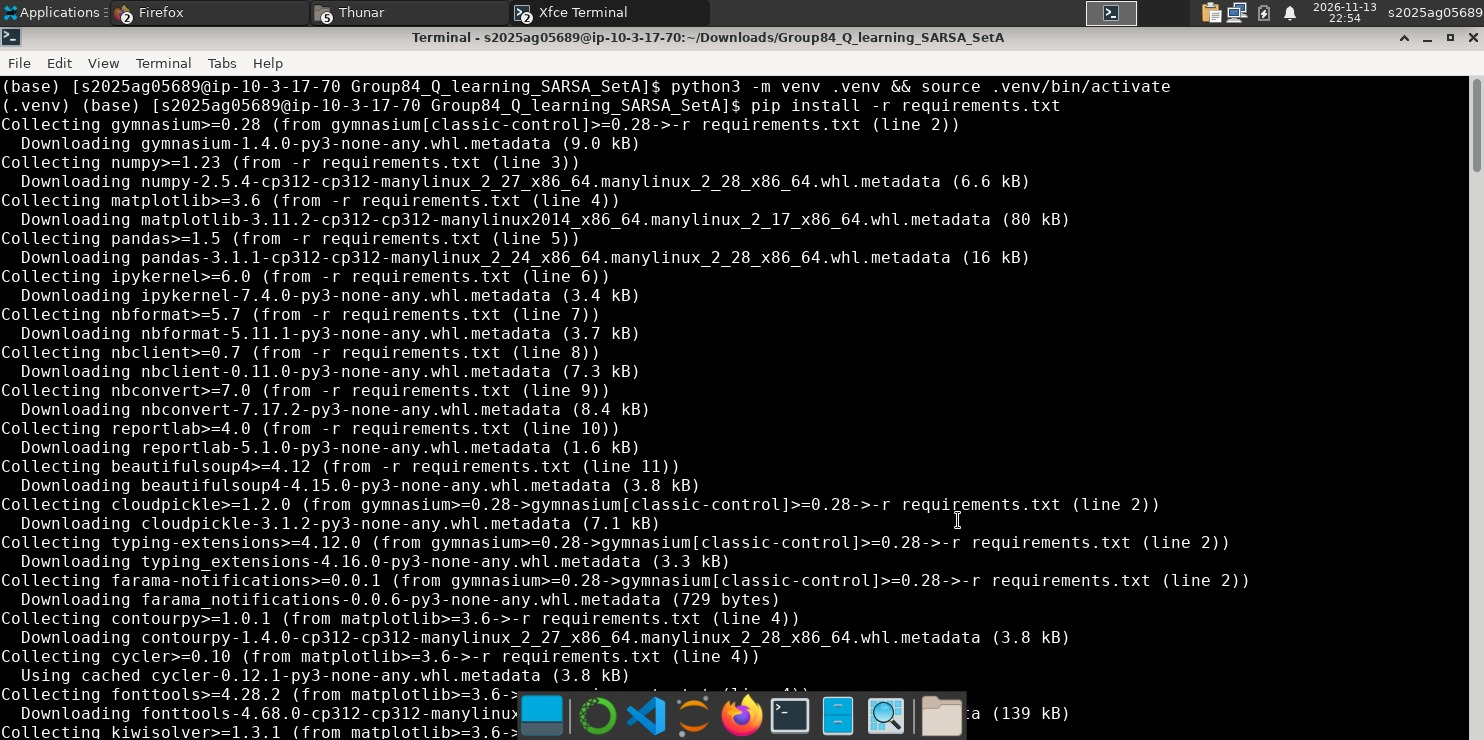

**Screenshot 2** (lab clock 2026-11-13 23:05): Notebook open in VS Code in the lab. The execution-record cell prints the time stamp 2026-11-13T23:04:45, the lab host name and the library versions.

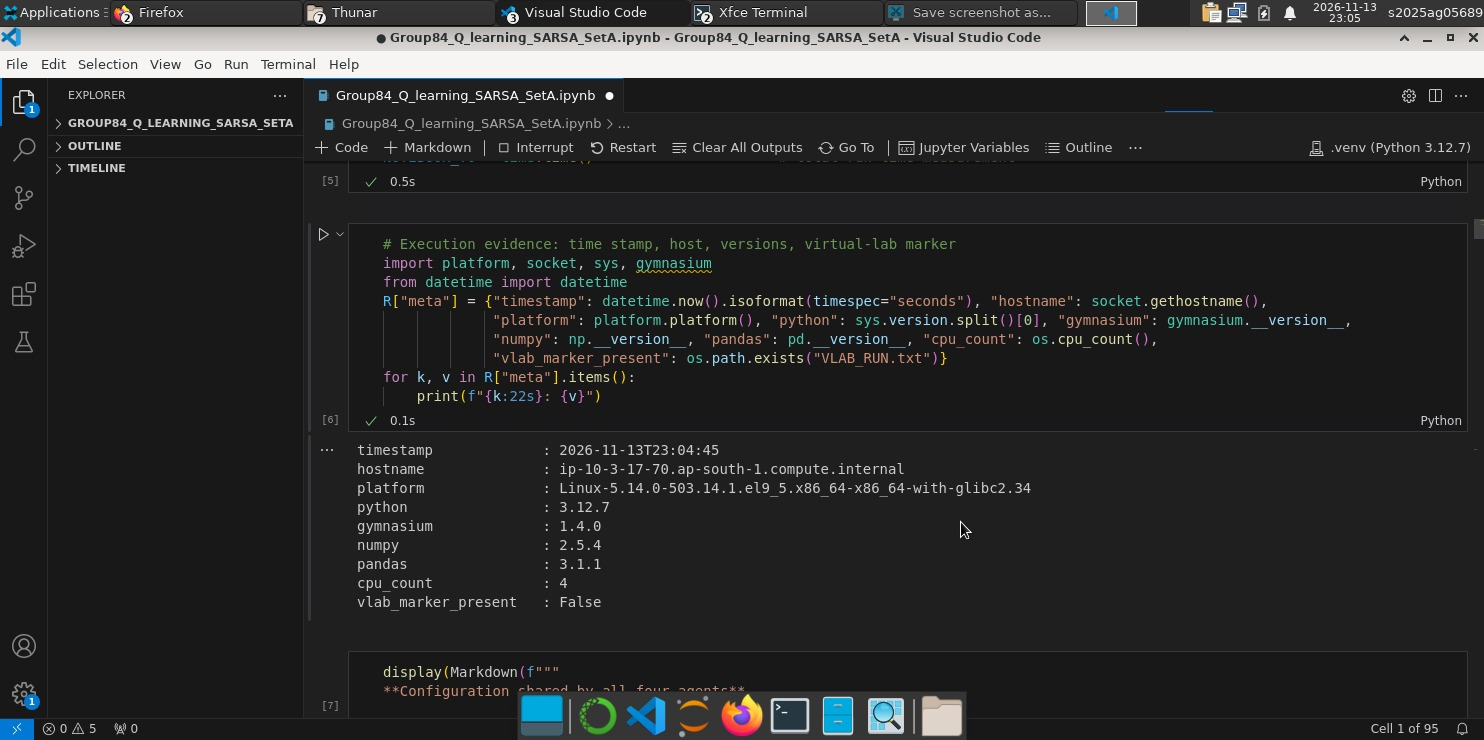

**Screenshot 3** (lab clock 2026-11-13 23:07): Section (b): Q-learning training on the original environment, with the progress log printed every 500 episodes.

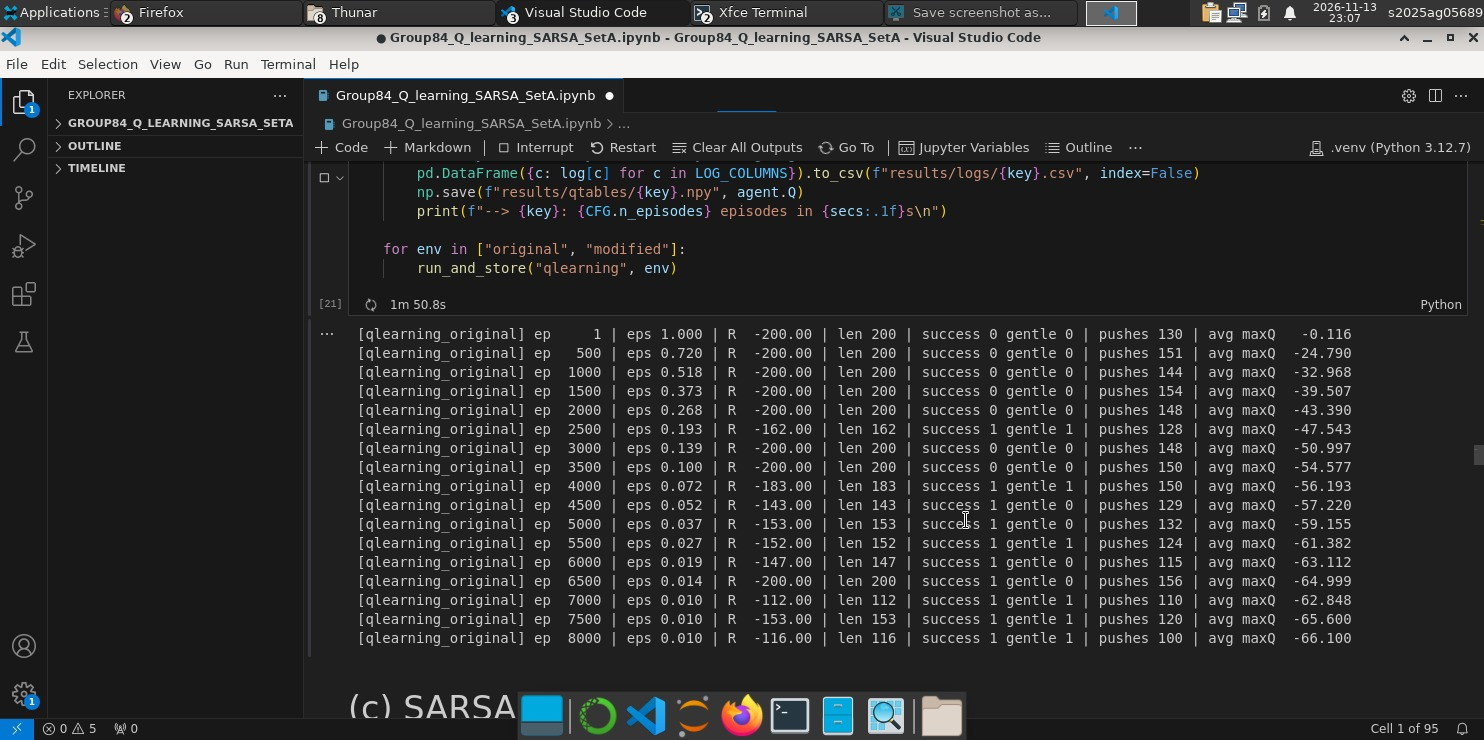

**Screenshot 4** (lab clock 2026-11-13 23:18): Section (d.1): reward-vs-episode figure produced in the lab.

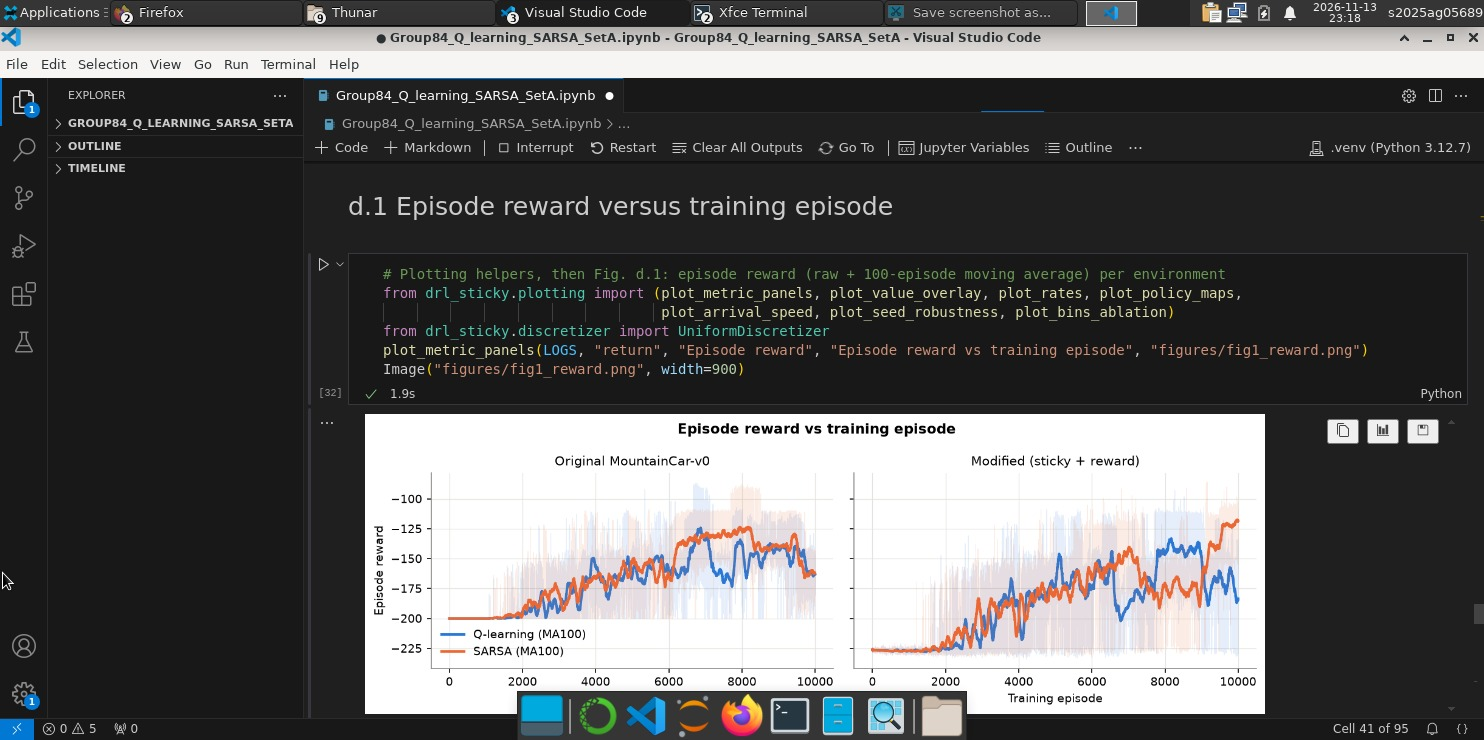

**Screenshot 5** (lab clock 2026-11-14 01:11): Section (d.6): greedy-policy evaluation table in the lab. The values match table d.6 of this report exactly.

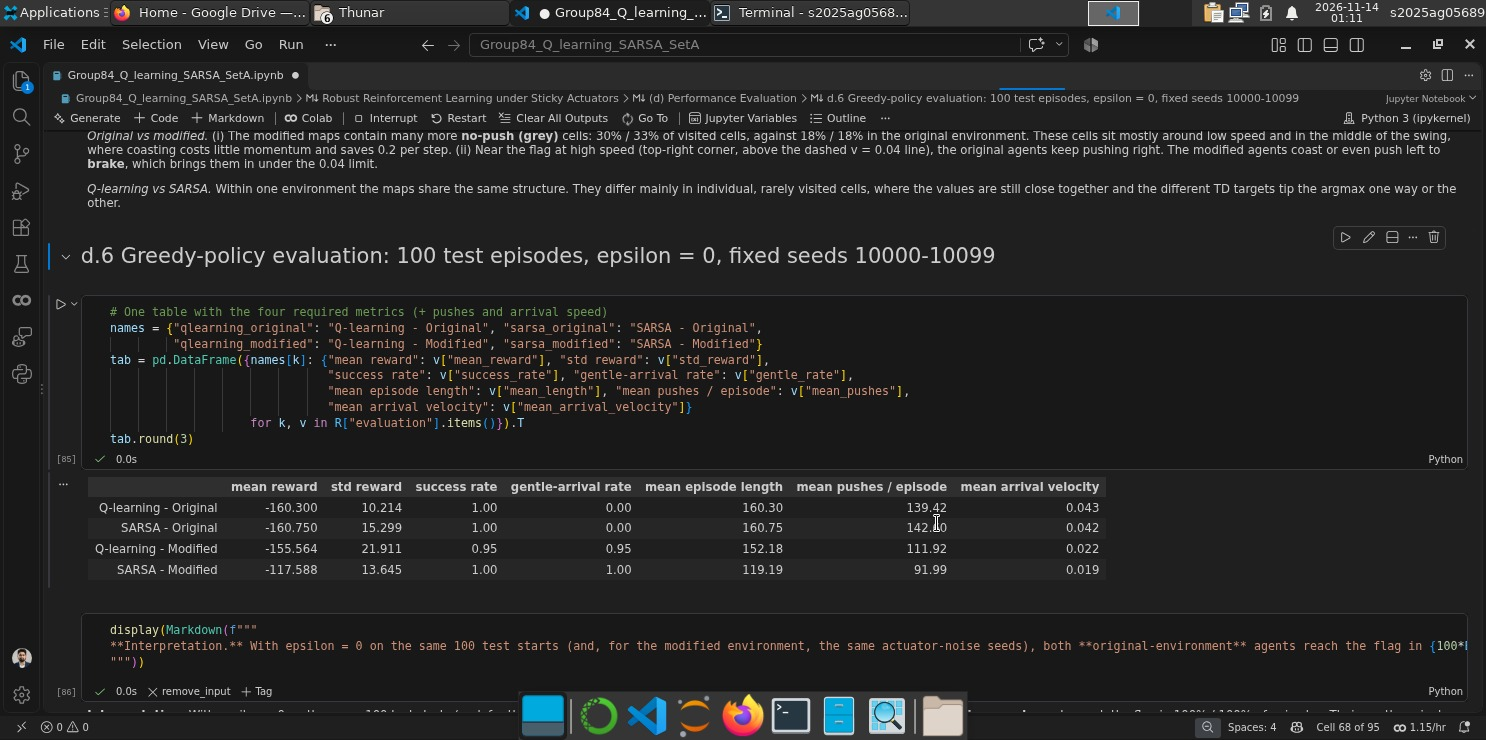

In [58]:
# Embed every virtual-lab screenshot in screenshots/ (sorted by capture order) with its caption
import glob, os
CAPTIONS = {
    "01": ("2026-11-13 22:54", "Lab terminal: project folder unpacked, virtual environment created and `pip install -r requirements.txt` running."),
    "02": ("2026-11-13 23:05", "Notebook open in VS Code in the lab. The execution-record cell prints the time stamp 2026-11-13T23:04:45, the lab host name and the library versions."),
    "03": ("2026-11-13 23:07", "Section (b): Q-learning training on the original environment, with the progress log printed every 500 episodes."),
    "04": ("2026-11-13 23:18", "Section (d.1): reward-vs-episode figure produced in the lab."),
    "05": ("2026-11-14 01:11", "Section (d.6): greedy-policy evaluation table in the lab. The values match table d.6 of this report exactly."),
}
shots = sorted(glob.glob("screenshots/*.png") + glob.glob("screenshots/*.jpg") + glob.glob("screenshots/*.jpeg"))
if os.path.exists("VLAB_RUN.txt"):
    display(Markdown("**Virtual-lab run record (`VLAB_RUN.txt`):**\n\n```\n" + open("VLAB_RUN.txt").read().strip() + "\n```"))
if not shots:
    display(Markdown("**TODO before submission:** add the timestamped virtual-lab screenshots to `screenshots/`."))
for i, s in enumerate(shots, 1):
    when, what = CAPTIONS.get(os.path.basename(s)[:2], ("see lab clock", os.path.basename(s)))
    display(Markdown(f"**Screenshot {i}** (lab clock {when}): {what}"))
    display(Image(s, width=820))

## Appendix A: Hyper-parameter pilot (`pilot_sweep.py`)
The pilot ran **before** the main study and used **different seeds** (master seeds 184, 284, 384 and evaluation seeds 50000+) from the final experiments (seed 84, evaluation seeds 10000+), so the reported test results were never used for tuning. It covered every combination of bins {20x20, 36x28, 40x40}, alpha {0.05, 0.1, 0.2}, epsilon-floor fraction {0.5, 0.7} and episodes {6000, 10000}, for both algorithms on the modified environment and 3 seeds each: 216 training runs. Below are the script and its top-10 configurations, ranked by mean greedy test reward.

In [59]:
# Print the full source of the hyper-parameter pilot script
print(open("pilot_sweep.py").read())

"""Hyper-parameter pilot (run BEFORE the main experiments).

Selects the discretization, learning rate, exploration-decay length and episode
budget used in the main study. To avoid tuning on the reported results, the pilot
uses different master seeds (184, 284, 384) and different evaluation seeds
(50000+ / 60000+) from the final experiments (seed 84, evaluation seeds 10000+).
Both algorithms are scored on the MODIFIED environment; the selection criterion
is the mean greedy-evaluation reward averaged over algorithms and seeds.

Usage:  python pilot_sweep.py          -> results/pilot.json
"""

from __future__ import annotations

import itertools
import os
from multiprocessing import Pool

import numpy as np

from drl_sticky.config import Config
from drl_sticky.evaluate import evaluate_greedy
from drl_sticky.train import sample_validation_states
from drl_sticky.train import train_agent
from drl_sticky.utils import save_json

BINS = [(20, 20), (36, 28), (40, 40)]        # candidate discret

In [60]:
# Top-10 pilot configurations ranked by mean greedy test reward (modified env, 3 pilot seeds x 2 algorithms)
pil = json.load(open("results/pilot.json"))
pd.DataFrame(pil["ranking"][:10]).round(3)

,bins,alpha,decay_frac,episodes,mean_eval_reward,mean_eval_success,mean_eval_gentle,q_eval_reward,sarsa_eval_reward
0,20x20,0.10,0.7,10000,-144.324,0.993,0.992,-135.409,-153.239
1,36x28,0.20,0.7,10000,-147.466,0.970,0.970,-147.198,-147.733
2,40x40,0.20,0.7,10000,-149.752,0.993,0.993,-145.724,-153.779
3,20x20,0.20,0.7,10000,-149.885,0.920,0.920,-140.542,-159.229
4,36x28,0.10,0.7,10000,-153.695,0.963,0.963,-151.701,-155.689
5,20x20,0.05,0.5,10000,-153.903,0.993,0.992,-154.618,-153.188
6,20x20,0.10,0.7,6000,-155.590,0.938,0.938,-153.653,-157.527
7,40x40,0.20,0.5,10000,-155.820,0.872,0.872,-169.561,-142.078
8,20x20,0.10,0.5,10000,-156.387,0.962,0.955,-159.179,-153.595
9,20x20,0.05,0.7,10000,-156.558,0.987,0.987,-170.985,-142.131


## Appendix B: Command-line entry point (`run_experiments.py`)
The same experiments can be run without Jupyter. This script calls exactly the functions used above.

In [61]:
# Print the full source of the command-line entry point
print(open("run_experiments.py").read())

"""Run EVERY experiment of the assignment from the command line and save all numbers/figures.

The master notebook runs exactly the same functions (drl_sticky.experiments) cell by cell;
this script is the non-interactive equivalent.

Outputs
  results/results.json          all reported numbers
  results/logs/<run>.csv        per-episode log of each of the 4 main runs (every iteration)
  results/qtables/<run>.npy     final Q-tables
  results/validation_states.npy fixed validation set (sampled once, before training)
  figures/*.png                 all plots

Usage:  python run_experiments.py [--episodes N] [--seeds 84 85 86 87 88] [--quick]
"""

from __future__ import annotations

import argparse
import os
import time

import numpy as np

from drl_sticky import experiments as X
from drl_sticky.config import Config
from drl_sticky.train import sample_validation_states
from drl_sticky.utils import save_json


def main() -> None:
    """Parse arguments and run blocks (a) -> (e) in order."""

## Appendix C: Training log covering every iteration (all 10,000 episodes of each agent)
Each row summarises one block of 100 consecutive training episodes, so every one of the 4 x 10,000 episodes is counted. **eps** = exploration rate at the end of the block. For each agent: **R** = mean episode reward, **succ** = % of episodes that reached the flag, **gentle** = % with a gentle arrival (v <= 0.04). The progress lines printed during training in (b) and (c) are the raw per-episode output; the full per-episode data (reward, length, pushes, avg max Q, sticky replacements) is saved in `results/logs/*.csv`.

In [62]:
# One compact table: every training episode of every agent, aggregated in blocks of 100 episodes
BLOCK = 100
names = {"qlearning_original": "Q-learning orig", "sarsa_original": "SARSA orig",
         "qlearning_modified": "Q-learning mod", "sarsa_modified": "SARSA mod"}
first = next(iter(LOGS.values()))
n = len(first["return"])
cols = {("", "episodes"): [f"{i+1}-{min(i+BLOCK, n)}" for i in range(0, n, BLOCK)],
        ("", "eps"): [f"{first['epsilon'][min(i+BLOCK, n)-1]:.3f}" for i in range(0, n, BLOCK)]}
for run, label in names.items():
    lg = LOGS[run]
    blocks = range(0, len(lg["return"]), BLOCK)
    cols[(label, "R")] = [np.mean(lg["return"][i:i+BLOCK]) for i in blocks]           # mean reward of the block
    cols[(label, "succ")] = [100 * np.mean(lg["success"][i:i+BLOCK]) for i in blocks]  # % reached the flag
    cols[(label, "gentle")] = [100 * np.mean(lg["gentle"][i:i+BLOCK]) for i in blocks] # % gentle arrivals
table = pd.DataFrame(cols)
table.columns = pd.MultiIndex.from_tuples(table.columns)
display(HTML("<div class='dense-log'>" + table.to_html(index=False, float_format=lambda v: f"{v:.1f}") + "</div>"))